# iGaming Media Buying Analytics — Q3 2026

## Executive Summary

**Scope.** Real, anonymized iGaming media buying data: Q3 acquisition cohorts, D30 outcomes, snapshot November 15, 2026.

**Quarter result.** Recorded spend was USD 479,600.57 and approved FTD volume was 9,740. Complete records cover 93.11% of recorded spend and yield USD 253,071.40 after advertising costs (56.67%). Missing conditional settlements select lower-return spend out of that total; the mean-cost sensitivity scenario yields 54.81%. Other operating costs are outside the dataset.

**Three findings**

1. LP_4529 has lower registration-to-FTD conversion in 37 of 38 concurrent within-campaign comparisons. It represents 16.43% of covered CPA spend at a 33.05% return. Removing its observations brings B_3's CPA return to 79.38%, close to B_1's 81.65%: landing mix matters for buyer comparisons.
2. Facebook's September 4–7 reporting episode accounts for 58 fewer FTDs and 166 fewer registrations than product records. Outside that window, matched FTD totals agree.
3. CPA / TikTok in BR, PE, and CL has positive campaign and monthly results, but acquisition costs rose. Conditional offers represent 48.90% of recorded spend; September OFF_6137 / CL is near its deposit threshold, with approximately USD 2,071 of fee exposure on known spend.

**Three actions**

1. Audit LP_4529 and randomize landing routing at fixed spend.
2. Repair reporting, recover missing expenses, and monitor conditional settlement headroom.
3. Confirm delivery capacity and recent unit economics before releasing staged next-cycle replication funds. The expense ledger remains budget-neutral; effect scenarios illustrate assumptions rather than forecast returns.

**Decision limit.** Observational comparisons guide tests. Causal setting effects, live account capacity, and full-quarter net profit require additional evidence.

## 1. Introduction

### Objective

Evaluate Q3 2026 acquisition performance and identify practical ways to improve traffic quality and advertising expense allocation.

### Questions

1. What are the quarterly result and monthly trends?
2. How do buyers compare within similar conditions?
3. Which GEOs, platforms, landings, and campaign settings warrant action?
4. Where do tracking and settlement quality limit decisions?
5. How should a fixed next-cycle expense envelope support validation tests?

Approved FTD volume is the paying-user guardrail; D30 repeat-depositor rate adds a quality measure. The planning constraint permits reassignment of up to 20% of recorded quarterly spend while preserving the expense envelope.

## 2. Data and Preparation

### 2.1. Source and Structure

This project analyzes real, anonymized iGaming media buying data.

Three CSV files contain launch settings, daily advertising statistics, and product acquisition cohorts. Monetary values are USD. Put the files in the same folder as this notebook, using the filenames below.

### campaigns.csv

A reference table containing acquisition launch settings and offer payment terms. Each row describes a launch identified by `launch_id`. Multiple launches may belong to the same campaign, and multiple offers may belong to the same brand.

| Column | Description |
|---|---|
| `launch_id` | Unique acquisition launch identifier. |
| `campaign_id` | Advertising campaign identifier. |
| `launch_date` | Launch start date. |
| `buyer_id` | Media buyer identifier. |
| `channel` | Advertising channel. |
| `platform` | Advertising platform or placement within the channel. |
| `geo` | Country targeted by the launch. |
| `device` | Targeted device type. |
| `landing_id` | Landing page identifier. |
| `creative_id` | Advertising creative identifier. |
| `creative_format` | Advertising creative format. |
| `audience_type` | Target audience type. |
| `age_group` | Age targeting settings, rather than the actual ages of acquired players. |
| `bid_strategy` | Campaign bidding strategy. |
| `optimization_goal` | Target action used for campaign optimization. |
| `campaign_daily_budget_usd` | Planned daily campaign budget in USD. Repeated across launches within the same campaign; must not be summed across launch rows. |
| `brand_id` | Brand identifier. A brand may have multiple offers. |
| `offer_id` | Offer identifier associated with a specific brand, country, and payment model. |
| `payout_model` | Payment model: CPA or budget reimbursement with a conditional spend-based fee. |
| `cpa_rate_usd` | Payment per approved first-time depositor in USD. Applicable only to CPA offers. |
| `minimum_qualifying_deposit_usd` | Minimum first deposit required for a player to qualify under the offer terms. |
| `spend_fee_rate` | Fee payable as a proportion of advertising spend when the deposit threshold is met. Not applicable to CPA offers. |
| `min_deposit_to_spend_ratio` | Minimum deposit-to-spend ratio required to earn the spend-based fee. Not applicable to CPA offers. |
| `budget_reimbursement_rate` | Proportion of advertising spend reimbursed separately from the acquisition fee. |
| `deposit_window_days` | Number of days after acquisition during which player deposits are counted. |
| `settlement_scope` | Settlement grouping: offer, country, and calendar month of player acquisition. |

Rates are stored as decimal fractions. For the conditional payment model, advertising spend is fully reimbursed regardless of performance. An additional fee of 30% of spend is earned if D30 deposits reach at least 60% of spend within the settlement group. The fee is then allocated to individual launches in proportion to their spend.

D30 deposits include deposits made during the first 30 days after acquisition; they are not calendar-month deposit totals.

### ad_stats_daily.csv

Daily advertising performance statistics. The expected level of detail is one row per date and launch. 

| Column | Description |
|---|---|
| `date` | Advertising activity date. |
| `launch_id` | Acquisition launch identifier. |
| `impressions` | Number of ad impressions. |
| `clicks` | Number of ad clicks. |
| `spend_usd` | Actual advertising spend in USD. |
| `platform_reported_registrations` | Registrations attributed by the advertising platform. |
| `platform_reported_ftd` | First-time depositors (FTDs) attributed by the advertising platform. |

### product_cohorts_daily.csv

A table containing acquisition cohort outcomes and calculated payments. Each row represents players acquired on a specific date through a specific launch. The combination of `acquisition_date` and `launch_id` uniquely identifies a row.

| Column | Description |
|---|---|
| `acquisition_date` | Date on which the players were acquired. |
| `launch_id` | Acquisition launch identifier used to join the campaign reference table. |
| `registrations` | Number of registered players attributed to the acquisition cohort. |
| `ftd_count` | Number of players who made their first deposit. |
| `approved_ftd_count` | Number of first-time depositors approved under the offer terms. |
| `repeat_depositors_d30` | Number of first-time depositors who made additional deposits within the first 30 days after acquisition. |
| `deposit_transactions_d30` | Total number of deposit transactions within the first 30 days after acquisition, including first and repeat deposits. |
| `first_deposit_amount_usd` | Total value of first deposits in USD. |
| `deposits_d30_usd` | Total value of first and repeat deposits within the first 30 days after acquisition, in USD. |
| `affiliate_revenue_usd` | Earned acquisition fee in USD: CPA payments or the conditional spend-based fee. Excludes budget reimbursement. |
| `active_users_d7` | Number of cohort players active on day 7 after acquisition. |
| `active_users_d30` | Number of cohort players active on day 30 after acquisition. |
| `data_as_of` | Date as of which cohort outcomes were measured. |
| `settlement_month` | Calendar month of player acquisition used for settlement grouping. |
| `settlement_group_id` | Identifier combining the offer, country, and acquisition month for payment calculations. |
| `budget_reimbursement_usd` | Advertising spend reimbursed separately from the acquisition fee. Zero for CPA offers. |
| `spend_fee_usd` | Conditional spend-based fee in USD. Already included in `affiliate_revenue_usd`; zero for CPA offers. |
| `total_receivable_usd` | Total amount receivable: budget reimbursement plus the acquisition fee. Represents an accrued payment, not confirmed cash received. |
| `settlement_status` | Calculation status indicating whether payment has been calculated or is pending due to missing advertising spend data. |

For CPA offers, the acquisition fee equals approved first-time depositors multiplied by the CPA rate.

For conditional spend-based offers, advertising spend is fully reimbursed. An additional fee of 30% of spend is earned when D30 deposits reach at least 60% of spend across the settlement group. Otherwise, the additional fee is zero.

If spend data is missing within a conditional settlement group, the fee and total receivable remain blank until the missing data is recovered. Blank values must not be treated as zero.

Player deposits are not revenue earned by the media buying team. Do not add `spend_fee_usd` to `affiliate_revenue_usd`, as it is already included.

### Execution Environment

Tested with the versions below. Code cells are formatted with Black 19.10b0 (88-character target width).

| Component | Version |
|---|---|
| Python | 3.9.7 |
| pandas | 1.3.4 |
| NumPy | 1.20.3 |
| Matplotlib | 3.4.3 |
| seaborn | 0.11.2 |
| nbformat | 5.1.3 |
| nbclient | 0.5.3 |

### 2.2. Load and Inspect

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 160)
campaigns = pd.read_csv("campaigns.csv")
ad_stats = pd.read_csv("ad_stats_daily.csv")
product_cohorts = pd.read_csv("product_cohorts_daily.csv")

for name, table in [
    ("campaigns", campaigns),
    ("ad_stats", ad_stats),
    ("product_cohorts", product_cohorts),
]:
    print(name, table.shape)
    display(table.head(3))
    print("Full duplicate rows:", int(table.duplicated().sum()))
    display(
        pd.DataFrame({"dtype": table.dtypes.astype(str), "missing": table.isna().sum()})
    )

campaigns (266, 26)


,launch_id,campaign_id,launch_date,buyer_id,channel,platform,geo,...,cpa_rate_usd,minimum_qualifying_deposit_usd,spend_fee_rate,min_deposit_to_spend_ratio,budget_reimbursement_rate,deposit_window_days,settlement_scope
0,LN_91021,CMP_4821,2026-08-15,B_1,Meta Ads,Facebook,PE,...,70.0,10,NaN,NaN,0,30,offer_geo_acquisition_month
1,LN_91022,CMP_4821,2026-08-15,B_1,Meta Ads,Facebook,PE,...,70.0,10,NaN,NaN,0,30,offer_geo_acquisition_month
2,LN_91024,CMP_4828,2026-07-20,B_2,Meta Ads,Facebook,BR,...,90.0,10,NaN,NaN,0,30,offer_geo_acquisition_month


Full duplicate rows: 0


,dtype,missing
launch_id,object,0
campaign_id,object,0
launch_date,object,0
buyer_id,object,0
channel,object,0
platform,object,0
geo,object,0
device,object,0
landing_id,object,0
creative_id,object,0


ad_stats (7983, 7)


,date,launch_id,impressions,clicks,spend_usd,platform_reported_registrations,platform_reported_ftd
0,2026-07-02,LN_91141,2740,53,77.86,2.0,0
1,2026-07-02,LN_91142,1800,36,66.88,2.0,0
2,2026-07-02,LN_91282,3355,64,59.66,8.0,4


... (2 outputs left out)

product_cohorts (7978, 19)


,acquisition_date,launch_id,registrations,ftd_count,approved_ftd_count,repeat_depositors_d30,deposit_transactions_d30,...,data_as_of,settlement_month,settlement_group_id,budget_reimbursement_usd,spend_fee_usd,total_receivable_usd,settlement_status
0,2026-07-02,LN_91141,2,0,0,0,0,...,2026-11-15,2026-07,OFF_6237_CL_2026-07,77.86,23.36,101.22,CALCULATED
1,2026-07-02,LN_91142,2,0,0,0,0,...,2026-11-15,2026-07,OFF_6237_CL_2026-07,66.88,20.06,86.94,CALCULATED
2,2026-07-02,LN_91282,8,4,3,1,6,...,2026-11-15,2026-07,OFF_6107_BR_2026-07,59.66,17.90,77.56,CALCULATED


Full duplicate rows: 0


,dtype,missing
acquisition_date,object,0
launch_id,object,0
registrations,int64,0
ftd_count,int64,0
approved_ftd_count,int64,0
repeat_depositors_d30,int64,0
deposit_transactions_d30,int64,0
first_deposit_amount_usd,float64,0
deposits_d30_usd,float64,0
affiliate_revenue_usd,float64,596


### 2.3. Types, Keys, and Missing Values

The inputs contain 266 launch rows, 7,983 advertising rows, and 7,978 product cohorts. Twelve advertising rows are exact copies. Missing CPA/conditional payment terms reflect different contracts. Missing platform events and unknown expenses retain their missing status.

In [2]:
# Convert dates and remove exact advertising duplicates
for table, column in [
    (campaigns, "launch_date"),
    (ad_stats, "date"),
    (product_cohorts, "acquisition_date"),
    (product_cohorts, "data_as_of"),
]:
    table[column] = pd.to_datetime(table[column], format="%Y-%m-%d", errors="raise")
removed_rows = int(ad_stats.duplicated().sum())
ad_stats = ad_stats.drop_duplicates().reset_index(drop=True)
campaigns["creative_format"] = campaigns["creative_format"].str.strip().str.title()
assert campaigns["launch_id"].is_unique
assert not ad_stats.duplicated(["date", "launch_id"]).any()
assert not product_cohorts.duplicated(["acquisition_date", "launch_id"]).any()
assert ad_stats["launch_id"].isin(campaigns["launch_id"]).all()
assert product_cohorts["launch_id"].isin(campaigns["launch_id"]).all()

# Validate the launch register's temporal coverage
first_dates = product_cohorts.groupby("launch_id")["acquisition_date"].min()
starts = campaigns.set_index("launch_id")["launch_date"].reindex(first_dates.index)
assert first_dates.eq(starts).all()
print("Exact duplicate rows removed:", removed_rows)
print(
    "Acquisition period:",
    product_cohorts["acquisition_date"].min().date(),
    "to",
    product_cohorts["acquisition_date"].max().date(),
)
print("Snapshot:", product_cohorts["data_as_of"].min().date())
display(
    campaigns.groupby("payout_model")[
        ["cpa_rate_usd", "spend_fee_rate", "min_deposit_to_spend_ratio"]
    ].agg(lambda s: s.isna().sum())
)

Exact duplicate rows removed: 12
Acquisition period: 2026-07-02 to 2026-09-30
Snapshot: 2026-11-15


,cpa_rate_usd,spend_fee_rate,min_deposit_to_spend_ratio
payout_model,,,
CPA,0,132,132
SPEND_FEE_CONDITIONAL,134,0,0


Every launch's first cohort matches its launch date; the earliest is July 2. The register therefore explains the available cohort start, while its scope leaves carry-over activity outside the case. All cohorts have over 30 days of elapsed follow-up by November 15.

`Video`/`video` and `Text`/`text` are standardized. Age labels such as `18+` and `25+` describe overlapping targeting settings, rather than exclusive player demographics.

In [3]:
# Preserve all product cohorts and attach one advertising row and one launch record
analysis_df = product_cohorts.merge(
    ad_stats,
    how="left",
    left_on=["acquisition_date", "launch_id"],
    right_on=["date", "launch_id"],
    validate="one_to_one",
    indicator="ad_data_match",
).merge(campaigns, on="launch_id", how="left", validate="many_to_one")
assert len(analysis_df) == len(product_cohorts)
assert analysis_df["ad_data_match"].eq("both").sum() == len(ad_stats)
analysis_df["financial_data_complete"] = (
    analysis_df["settlement_status"].eq("CALCULATED")
    & analysis_df["spend_usd"].notna()
    & analysis_df["total_receivable_usd"].notna()
)
analysis_df["result_after_ads_usd"] = (
    analysis_df["total_receivable_usd"] - analysis_df["spend_usd"]
).where(analysis_df["financial_data_complete"])
analysis_df["acquisition_month"] = analysis_df["acquisition_date"].dt.to_period("M")
display(pd.crosstab(analysis_df["settlement_status"], analysis_df["ad_data_match"]))
coverage = analysis_df["financial_data_complete"].value_counts().to_frame("rows")
coverage["share_pct"] = coverage["rows"] / len(analysis_df) * 100
display(coverage.round(2))

ad_data_match,left_only,both
settlement_status,,
CALCULATED,2,7380
PENDING_MISSING_SPEND,5,591


,rows,share_pct
True,7380,92.5
False,598,7.5


Seven product cohorts lack advertising records: five conditional cohorts affect four entire settlement groups (596 pending rows), and two CPA cohorts have calculated payouts but unknown expenses. There are 16 missing platform registration counts. Complete financial inputs cover 7,380 cohorts; product outcomes remain available for all cohorts.

### 2.4. Numerical and Accounting Validation

In [4]:
# Test within-row logic and accounting identities
checks = {
    "clicks_above_impressions": (ad_stats["clicks"] > ad_stats["impressions"]).sum(),
    "ftds_above_registrations": (
        product_cohorts["ftd_count"] > product_cohorts["registrations"]
    ).sum(),
    "approved_above_ftds": (
        product_cohorts["approved_ftd_count"] > product_cohorts["ftd_count"]
    ).sum(),
    "repeat_above_ftds": (
        product_cohorts["repeat_depositors_d30"] > product_cohorts["ftd_count"]
    ).sum(),
    "transactions_below_ftds": (
        product_cohorts["deposit_transactions_d30"] < product_cohorts["ftd_count"]
    ).sum(),
    "d30_below_first_deposits": (
        product_cohorts["deposits_d30_usd"] + 0.01
        < product_cohorts["first_deposit_amount_usd"]
    ).sum(),
    "d7_active_above_registrations": (
        product_cohorts["active_users_d7"] > product_cohorts["registrations"]
    ).sum(),
    "d30_active_above_registrations": (
        product_cohorts["active_users_d30"] > product_cohorts["registrations"]
    ).sum(),
}
assert not any(checks.values())
for table in [campaigns, ad_stats, product_cohorts]:
    assert not table.select_dtypes("number").lt(0).any().any()
calculated = analysis_df.loc[analysis_df["settlement_status"].eq("CALCULATED")]
assert (
    (
        calculated["total_receivable_usd"]
        - calculated["budget_reimbursement_usd"]
        - calculated["affiliate_revenue_usd"]
    )
    .abs()
    .le(0.010001)
    .all()
)
cpa = calculated.loc[calculated["payout_model"].eq("CPA")]
assert (
    (cpa["affiliate_revenue_usd"] - cpa["approved_ftd_count"] * cpa["cpa_rate_usd"])
    .abs()
    .le(0.010001)
    .all()
)
conditional = calculated.loc[calculated["payout_model"].eq("SPEND_FEE_CONDITIONAL")]
assert (
    (conditional["affiliate_revenue_usd"] - conditional["spend_fee_usd"])
    .abs()
    .le(0.010001)
    .all()
)
display(pd.Series(checks).to_frame("flagged_rows"))
print("Accounting identities: passed")

,flagged_rows
clicks_above_impressions,0
ftds_above_registrations,0
approved_above_ftds,0
repeat_above_ftds,0
transactions_below_ftds,0
d30_below_first_deposits,0
d7_active_above_registrations,0
d30_active_above_registrations,0


Accounting identities: passed


The checked counts and accounting identities agree. Total receivable equals reimbursement plus acquisition fee. The spend fee is already included in affiliate revenue. Player deposits measure offer performance; accrued receivables measure payments owed to the buying team.

## 3. Metric Definitions and Reusable Aggregation

| Metric | Calculation and scope |
|---|---|
| CTR (%) | Clicks / impressions × 100, on matched advertising rows |
| CPC (USD) | Recorded spend / clicks, on the same matched rows |
| Registration-to-FTD (%) | Product FTDs / product registrations × 100 |
| Approval rate (%) | Approved FTDs / FTDs × 100 |
| Repeat-depositor rate D30 (%) | Repeat depositors / FTDs × 100 |
| Cost per approved FTD | Spend / approved FTDs on financially complete rows |
| Result after ads | Total receivable − spend on financially complete rows |
| Return after ads (%) | Result after ads / spend × 100 on financially complete rows |
| Financial spend coverage (%) | Complete-row spend / all recorded spend × 100 |

Ratios use aggregated numerators and denominators from the same record set. Zero denominators remain undefined. Upper-funnel events use platform activity; product conversion uses acquisition cohorts, so these are complementary diagnostics rather than a linked user-level funnel. Financial results exclude other operating costs.

In [5]:
def safe_ratio(numerator, denominator, multiplier=1):
    return numerator / denominator * multiplier if denominator != 0 else float("nan")


def divide(numerator, denominator, scale=1):
    return numerator.div(denominator.replace(0, np.nan)) * scale


def summarize(data, by):
    """Aggregate volume on all cohorts; advertising and finance on matching subsets."""
    by = [by] if isinstance(by, str) else list(by)
    totals = data.groupby(by, observed=True).agg(
        cohorts=("launch_id", "size"),
        campaigns=("campaign_id", "nunique"),
        launches=("launch_id", "nunique"),
        registrations=("registrations", "sum"),
        ftds=("ftd_count", "sum"),
        approved_ftds=("approved_ftd_count", "sum"),
        repeat_depositors=("repeat_depositors_d30", "sum"),
        complete_cohorts=("financial_data_complete", "sum"),
    )
    ads = (
        data.loc[data["ad_data_match"].eq("both")]
        .groupby(by, observed=True)
        .agg(
            recorded_spend=("spend_usd", lambda s: s.sum(min_count=1)),
            impressions=("impressions", "sum"),
            clicks=("clicks", "sum"),
        )
    )
    finance = (
        data.loc[data["financial_data_complete"]]
        .groupby(by, observed=True)
        .agg(
            covered_spend=("spend_usd", "sum"),
            covered_approved_ftds=("approved_ftd_count", "sum"),
            receivable=("total_receivable_usd", "sum"),
            result=("result_after_ads_usd", "sum"),
        )
    )
    out = totals.join(ads).join(finance)
    out["ctr_pct"] = divide(out["clicks"], out["impressions"], 100)
    out["cpc_usd"] = divide(out["recorded_spend"], out["clicks"])
    out["reg_to_ftd_pct"] = divide(out["ftds"], out["registrations"], 100)
    out["approval_pct"] = divide(out["approved_ftds"], out["ftds"], 100)
    out["repeat_pct"] = divide(out["repeat_depositors"], out["ftds"], 100)
    out["cost_approved_ftd"] = divide(
        out["covered_spend"], out["covered_approved_ftds"]
    )
    out["return_pct"] = divide(out["result"], out["covered_spend"], 100)
    out["spend_coverage_pct"] = divide(out["covered_spend"], out["recorded_spend"], 100)
    out["cohort_coverage_pct"] = divide(out["complete_cohorts"], out["cohorts"], 100)
    return out


def show(table, columns):
    display(table[columns].round(2))


core = [
    "campaigns",
    "recorded_spend",
    "approved_ftds",
    "result",
    "return_pct",
    "cost_approved_ftd",
    "repeat_pct",
    "spend_coverage_pct",
]
cpa_data = analysis_df.loc[analysis_df["payout_model"].eq("CPA")].copy()

## 4. Performance Analysis

### 4.1. Quarter and Monthly Trends

,recorded_spend,registrations,ftds,approved_ftds,reg_to_ftd_pct,approval_pct,repeat_pct,covered_spend,receivable,result,return_pct,spend_coverage_pct
period,,,,,,,,,,,,
Q3 2026,479600.57,34252,10810,9740,31.56,90.1,48.43,446544.92,699616.32,253071.4,56.67,93.11


,recorded_spend,approved_ftds,result,return_pct,reg_to_ftd_pct,spend_coverage_pct
acquisition_month,,,,,,
2026-07,120722.09,2891,74162.42,67.92,32.96,90.44
2026-08,217908.39,4135,108440.48,49.76,31.13,100.00
2026-09,140970.09,2714,70468.50,58.99,30.81,84.74


recorded_spend    result  return_pct  spend_coverage_pct
acquisition_month payout_model                                                                   
2026-07           CPA                          57915.18  59174.82      102.17              100.00
                  SPEND_FEE_CONDITIONAL        62806.91  14987.60       29.23               81.63
2026-08           CPA                         112171.10  76718.90       68.39              100.00
                  SPEND_FEE_CONDITIONAL       105737.29  31721.58       30.00              100.00
2026-09           CPA                          75005.35  57134.65       76.17              100.00
                  SPEND_FEE_CONDITIONAL        65964.74  13333.85       30.00               67.38

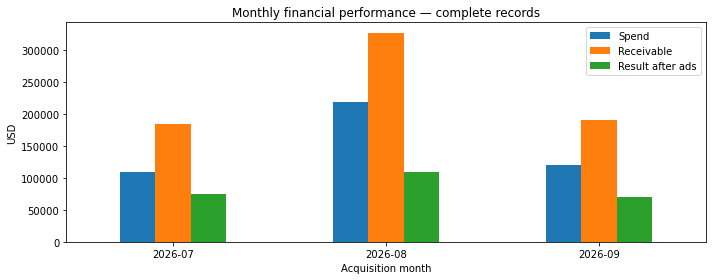

In [6]:
quarter = summarize(analysis_df.assign(period="Q3 2026"), "period")
show(
    quarter,
    [
        "recorded_spend",
        "registrations",
        "ftds",
        "approved_ftds",
        "reg_to_ftd_pct",
        "approval_pct",
        "repeat_pct",
        "covered_spend",
        "receivable",
        "result",
        "return_pct",
        "spend_coverage_pct",
    ],
)
monthly = summarize(analysis_df, "acquisition_month")
show(
    monthly,
    [
        "recorded_spend",
        "approved_ftds",
        "result",
        "return_pct",
        "reg_to_ftd_pct",
        "spend_coverage_pct",
    ],
)
monthly_model = summarize(analysis_df, ["acquisition_month", "payout_model"])
show(monthly_model, ["recorded_spend", "result", "return_pct", "spend_coverage_pct"])
plot_data = monthly[["covered_spend", "receivable", "result"]].copy()
plot_data.index = plot_data.index.astype(str)
ax = plot_data.rename(
    columns={
        "covered_spend": "Spend",
        "receivable": "Receivable",
        "result": "Result after ads",
    }
).plot.bar(figsize=(10, 4), rot=0)
ax.set(
    title="Monthly financial performance — complete records",
    xlabel="Acquisition month",
    ylabel="USD",
)
plt.tight_layout()
plt.show()

Recorded spend was USD 479,600.57; complete rows yielded USD 253,071.40 after ads at a 56.67% return. August had the largest spend and approved-FTD volume. Product registration-to-FTD conversion fell from 32.96% in July to 30.81% in September.

CPA return fell from 102.17% to 68.39%, then recovered to 76.17%. The deterioration persists within one payment model. Mixed monthly returns also reflect unequal conditional-settlement coverage, addressed in the sensitivity analysis below.

### 4.2. Upper Funnel and Platform Economics

In [7]:
platform_overview = summarize(analysis_df, ["payout_model", "platform"])
show(
    platform_overview,
    [
        "campaigns",
        "recorded_spend",
        "impressions",
        "clicks",
        "ctr_pct",
        "cpc_usd",
        "reg_to_ftd_pct",
        "return_pct",
        "spend_coverage_pct",
    ],
)
cpa_platforms = summarize(cpa_data, ["geo", "platform"])
show(cpa_platforms, core)

campaigns  recorded_spend  impressions   clicks  ctr_pct  cpc_usd  reg_to_ftd_pct  return_pct  spend_coverage_pct
payout_model          platform                                                                                                                    
CPA                   Facebook           7        32532.14    1804030.0  26619.0     1.48     1.22           37.91      101.28              100.00
                      Instagram          8        35666.04    1747351.0  26565.0     1.52     1.34           30.46       54.80              100.00
                      Search            12        45461.56     481790.0  26649.0     5.53     1.71           28.46       23.12              100.00
                      TikTok            21        83257.98    3512734.0  72859.0     2.07     1.14           29.55      121.50              100.00
                      YouTube           12        48173.91    1926086.0  29051.0     1.51     1.66           32.10       59.92              100.00
SPEND_FEE_CONDITIONAL Facebook           7        28594.36    1216997.0  18101.0     1.49     1.58           34.15       30.00               76.12
                      Instagram         11        47568.77    2088908.0  32017.0     1.53     1.49           29.18       30.00               84.20
                      Search             8        25381.53     275224.0  15088.0     5.48     1.68           31.56       30.00               85.25
                      TikTok            25       105015.28    4741796.0  95108.0     2.01     1.10           33.34       29.59               91.84
                      YouTube            9        27949.00    1306697.0  19160.0     1.47     1.46           28.53       30.00               77.11

campaigns  recorded_spend  approved_ftds    result  return_pct  cost_approved_ftd  repeat_pct  spend_coverage_pct
geo platform                                                                                                                    
BR  Facebook           2        12872.37            303  14397.63      111.85              42.48       47.95               100.0
    Instagram          1         3545.66             52   1134.34       31.99              68.19       41.38               100.0
    Search             1         2239.66             35    910.34       40.65              63.99       44.74               100.0
    TikTok             6        23576.25            653  35193.75      149.28              36.10       51.82               100.0
    YouTube            1         3979.40             76   2860.60       71.89              52.36       36.47               100.0
CL  Facebook           1         1476.56             35   3073.44      208.15              42.19       36.84               100.0
    Instagram          2         9199.81             93   2890.19       31.42              98.92       48.08               100.0
    Search             4        16701.26            147   2408.74       14.42             113.61       46.63               100.0
    TikTok             5        23125.55            393  27964.45      120.92              58.84       47.38               100.0
    YouTube            7        27727.74            324  14392.26       51.91              85.58       44.88               100.0
MX  Facebook           1         1708.81             12   -388.81      -22.75             142.40       57.14               100.0
    Instagram          1         6490.04             79   2199.96       33.90              82.15       39.02               100.0
    Search             2         6314.40             71   1495.60       23.69              88.94       50.00               100.0
    TikTok             4        14095.65            205   8454.35       59.98              68.76       47.32               100.0
    YouTube            2         5193.65             65   1956.35       37.67              79.90       50.68               100.0
PE  Facebook           3        16474.40            462  15865.60       96.30              35.66       50.88               100.0
    Instagram          4        16430.53            427  13319.47       81.07              38.66       46.78               100.0
    Search             5        20206.24            370   5693.76       28.18              54.61       48.74               100.0
    TikTok             6        22460.53            743  29549.47      131.56              30.23       46.94               100.0
    YouTube            2        11273.12            299   9656.88       85.66              37.70       48.20               100.0

CTR and CPC describe delivery efficiency; approved-FTD cost and financial return determine acquisition economics. CPA / Search has a 5.53% CTR but only a 23.12% return, while TikTok has a 2.07% CTR, USD 1.14 CPC, and 121.50% return. A high click rate alone therefore fails to identify the stronger acquisition economics. Search clicks and video impressions serve different acquisition paths, so interpret these aggregates in context.

CL / Google combines Search at 14.42% return on USD 16,701.26 spend with YouTube at 51.91% on USD 27,727.74. Search trails YouTube within all four GEOs, while other platforms can be weaker than Search. Separate platform and landing composition before assigning budget changes.

### 4.3. Settlement Rules and Conditional-model Actions

In [8]:
conditional_data = analysis_df.loc[
    analysis_df["payout_model"].eq("SPEND_FEE_CONDITIONAL")
].copy()
settlements = conditional_data.groupby("settlement_group_id").agg(
    rows=("launch_id", "size"),
    known_spend=("spend_usd", "sum"),
    missing_days=("spend_usd", lambda s: s.isna().sum()),
    pending_rows=("settlement_status", lambda s: s.ne("CALCULATED").sum()),
    deposits=("deposits_d30_usd", "sum"),
    actual_fee=("spend_fee_usd", lambda s: s.sum(min_count=1)),
    threshold=("min_deposit_to_spend_ratio", "first"),
    rate=("spend_fee_rate", "first"),
)
settlements["observed_ratio"] = settlements["deposits"] / settlements["known_spend"]
settlements["unknown_spend_headroom"] = (
    settlements["deposits"] / settlements["threshold"] - settlements["known_spend"]
)
settlements["fee_on_known_spend"] = settlements["known_spend"] * settlements["rate"]
resolved = settlements["missing_days"].eq(0) & settlements["pending_rows"].eq(0)
settlements["eligible"] = (
    settlements["observed_ratio"]
    .ge(settlements["threshold"])
    .astype("boolean")
    .where(resolved)
)
settlements["expected_fee"] = (
    (settlements["known_spend"] * settlements["rate"])
    .where(settlements["eligible"].fillna(False), 0)
    .where(resolved)
)
tolerance = settlements["rows"] * 0.005 + 1e-8
assert (
    (
        settlements.loc[resolved, "actual_fee"]
        - settlements.loc[resolved, "expected_fee"]
    )
    .abs()
    .le(tolerance[resolved])
    .all()
)
mapped_eligible = (
    conditional_data["settlement_group_id"].map(settlements["eligible"]).fillna(False)
)
resolved_rows = conditional_data["settlement_group_id"].isin(
    settlements.index[resolved]
)
expected = (conditional_data["spend_usd"] * conditional_data["spend_fee_rate"]).where(
    mapped_eligible, 0
)
assert (
    (conditional_data.loc[resolved_rows, "spend_fee_usd"] - expected[resolved_rows])
    .abs()
    .le(0.005001)
    .all()
)
print(
    "Resolved groups:", int(resolved.sum()), "Pending groups:", int((~resolved).sum())
)
print(
    "Conditional share of recorded spend (%):",
    round(
        conditional_data["spend_usd"].sum() / analysis_df["spend_usd"].sum() * 100, 2
    ),
)
display(
    settlements[
        [
            "known_spend",
            "missing_days",
            "deposits",
            "observed_ratio",
            "threshold",
            "unknown_spend_headroom",
            "actual_fee",
            "fee_on_known_spend",
        ]
    ].round(2)
)

Resolved groups: 29 Pending groups: 4
Conditional share of recorded spend (%): 48.9


,known_spend,missing_days,deposits,observed_ratio,threshold,unknown_spend_headroom,actual_fee,fee_on_known_spend
settlement_group_id,,,,,,,,
OFF_6107_BR_2026-07,11292.67,0,26077.36,2.31,0.6,32169.60,3387.84,3387.80
OFF_6107_BR_2026-08,4537.15,0,7332.74,1.62,0.6,7684.08,1361.12,1361.14
OFF_6117_MX_2026-07,707.18,0,1089.38,1.54,0.6,1108.45,212.17,212.15
OFF_6117_MX_2026-08,16871.52,0,25787.27,1.53,0.6,26107.26,5061.55,5061.46
OFF_6117_MX_2026-09,7587.04,0,12980.15,1.71,0.6,14046.54,2276.11,2276.11
OFF_6127_PE_2026-07,4117.36,0,13343.83,3.24,0.6,18122.36,1235.23,1235.21
OFF_6127_PE_2026-08,9293.74,0,19245.65,2.07,0.6,22782.34,2788.14,2788.12
OFF_6127_PE_2026-09,7684.14,0,19850.94,2.58,0.6,25400.76,2305.22,2305.24
OFF_6137_CL_2026-07,1311.93,0,554.57,0.42,0.6,-387.65,0.00,393.58


Conditional offers represent **48.90% of recorded spend**. Twenty-nine resolved groups match the fee rules; four remain pending. July OFF_6137 / CL missed the 0.60 threshold: expenses were reimbursed and its fee was zero. This also explains B_4's 29.55% covered conditional return.

**Action:** monitor deposit-to-spend ratio, threshold headroom, projected final spend, and the amount of fee exposed at the complete offer/GEO/acquisition-month level. September OFF_6137 / CL has an observed ratio of 0.707 and USD 1,227.92 of additional unknown-spend headroom. Approximately **USD 2,070.94 of fee on known spend** depends on eligibility; missing spend changes both the ratio and final fee.

Use 0.75 as an illustrative early-warning buffer above the 0.60 contract threshold. The September CL group already triggers this review. Recover its missing expense, inspect deposits and attribution, and hold incremental spend until projected settlement eligibility is reviewed. Other pending groups also require reconciliation. Reimbursement limits advertising-cost exposure here, while the conditional fee and operating margin remain at risk.

### 4.4. Financial Coverage and Sensitivity

In [9]:
# Preserve actual data; build separate settlement scenarios
pending_source = analysis_df.loc[
    analysis_df["payout_model"].eq("SPEND_FEE_CONDITIONAL")
]
pending_groups = pending_source.groupby("settlement_group_id").agg(
    observed_spend=("spend_usd", "sum"),
    deposits=("deposits_d30_usd", "sum"),
    missing_days=("spend_usd", lambda s: s.isna().sum()),
    pending_rows=("settlement_status", lambda s: s.ne("CALCULATED").sum()),
    threshold=("min_deposit_to_spend_ratio", "first"),
)
pending_groups = pending_groups.loc[pending_groups["pending_rows"].gt(0)].copy()
pending_groups["observed_deposit_ratio"] = (
    pending_groups["deposits"] / pending_groups["observed_spend"]
)
pending_groups["missing_spend_headroom"] = (
    pending_groups["deposits"] / pending_groups["threshold"]
    - pending_groups["observed_spend"]
)
display(pending_groups.round(2))
print(
    "Maximum observed launch-day spend (not a bound):",
    round(analysis_df["spend_usd"].max(), 2),
)

launch_mean_spend = analysis_df.groupby("launch_id")["spend_usd"].mean()
scenario_frames = {}
scenario_totals = []
for label, factor, force_no_fee in [
    ("Half launch mean", 0.5, False),
    ("Launch mean", 1.0, False),
    ("Twice launch mean", 2.0, False),
    ("Launch mean; no pending fee", 1.0, True),
]:
    scenario = analysis_df.copy()
    missing = scenario["spend_usd"].isna()
    scenario["estimated_missing_spend"] = (
        scenario["launch_id"].map(launch_mean_spend) * factor
    ).where(missing, 0)
    assert scenario.loc[missing, "estimated_missing_spend"].notna().all()
    scenario["scenario_spend"] = scenario["spend_usd"].fillna(
        scenario["estimated_missing_spend"]
    )
    conditional = scenario["payout_model"].eq("SPEND_FEE_CONDITIONAL")
    sg = (
        scenario.loc[conditional]
        .groupby("settlement_group_id")
        .agg(
            spend=("scenario_spend", "sum"),
            deposits=("deposits_d30_usd", "sum"),
            threshold=("min_deposit_to_spend_ratio", "first"),
        )
    )
    eligible = sg["deposits"].ge(sg["spend"] * sg["threshold"])
    pending = scenario["settlement_status"].ne("CALCULATED")
    fee_eligible = scenario["settlement_group_id"].map(eligible).fillna(False)
    if force_no_fee:
        fee_eligible.loc[pending] = False
    scenario["scenario_receivable"] = scenario["total_receivable_usd"].copy()
    scenario.loc[pending, "scenario_receivable"] = (
        scenario.loc[pending, "scenario_spend"]
        * (
            scenario.loc[pending, "budget_reimbursement_rate"]
            + scenario.loc[pending, "spend_fee_rate"] * fee_eligible.loc[pending]
        )
    ).round(2)
    scenario["scenario_result"] = (
        scenario["scenario_receivable"] - scenario["scenario_spend"]
    )
    assert scenario["scenario_result"].notna().all()
    scenario_frames[label] = scenario
    scenario_totals.append(
        {
            "scenario": label,
            "estimated_missing_spend": scenario["estimated_missing_spend"].sum(),
            "scenario_total_spend": scenario["scenario_spend"].sum(),
            "scenario_result": scenario["scenario_result"].sum(),
            "return_pct": safe_ratio(
                scenario["scenario_result"].sum(), scenario["scenario_spend"].sum(), 100
            ),
            "pending_groups_with_assumed_fee": int(
                eligible.reindex(pending_groups.index).sum()
            )
            if not force_no_fee
            else 0,
        }
    )
scenario_totals = pd.DataFrame(scenario_totals).set_index("scenario")
display(scenario_totals.round(2))

,observed_spend,deposits,missing_days,pending_rows,threshold,observed_deposit_ratio,missing_spend_headroom
settlement_group_id,,,,,,,
OFF_6137_CL_2026-09,6903.13,4878.63,1,124,0.6,0.71,1227.92
OFF_6217_MX_2026-09,2326.29,3026.71,2,90,0.6,1.30,2718.23
OFF_6227_PE_2026-07,11537.00,23637.13,1,192,0.6,2.05,27858.22
OFF_6227_PE_2026-09,12289.23,19555.67,1,190,0.6,1.59,20303.55


Maximum observed launch-day spend (not a bound): 126.98


,estimated_missing_spend,scenario_total_spend,scenario_result,return_pct,pending_groups_with_assumed_fee
scenario,,,,,
Half launch mean,209.13,479809.70,263113.67,54.84,4
Launch mean,418.25,480018.82,263099.22,54.81,4
Twice launch mean,836.51,480437.08,263070.28,54.76,4
Launch mean; no pending fee,418.25,480018.82,253092.63,52.73,0


In [10]:
mean_scenario = scenario_frames["Launch mean"]
for key in ["buyer_id", "acquisition_month"]:
    scenario_group = mean_scenario.groupby(key).agg(
        spend=("scenario_spend", "sum"), result=("scenario_result", "sum")
    )
    scenario_group["assumed_return_pct"] = (
        scenario_group["result"] / scenario_group["spend"] * 100
    )
    scenario_group["covered_return_pct"] = summarize(analysis_df, key)["return_pct"]
    print(key)
    display(scenario_group.round(2))

buyer_id


,spend,result,assumed_return_pct,covered_return_pct
buyer_id,,,,
B_1,121147.76,75306.62,62.16,66.69
B_2,128453.36,87423.87,68.06,69.73
B_3,103948.37,55341.59,53.24,56.15
B_4,126469.33,45027.14,35.60,35.67


acquisition_month


,spend,result,assumed_return_pct,covered_return_pct
acquisition_month,,,,
2026-07,120808.25,77649.38,64.27,67.92
2026-08,217992.48,108496.39,49.77,49.76
2026-09,141218.09,76953.45,54.49,58.99


Complete-record returns select out conditional spend with lower contractual returns. The 56.67% covered quarterly return therefore overstates the plausible mixed return under the tested fee/cost assumptions.

Estimate missing launch-day cost from that launch's mean, then test half and twice that estimate. All four pending groups remain above threshold. The quarterly scenario returns are 54.84%, 54.81%, and 54.76%; a deliberately adverse zero-pending-fee case gives 52.73%. These are sensitivity cases, not recovered financial facts or confidence bounds. The maximum observed day is a reference rather than a bound on unknown expenses.

The mean-cost scenario gives about 64.3%, 49.8%, and 54.5% by month. Buyer shifts are unequal because missingness is concentrated in particular conditional portfolios. Keep actual and scenario columns distinct.

### 4.5. Buyer Performance and Comparable Segments

,campaigns,recorded_spend,approved_ftds,result,return_pct,cost_approved_ftd,repeat_pct,spend_coverage_pct
buyer_id,,,,,,,,
B_1,30,120872.02,2243,70898.92,66.69,57.84,48.14,87.95
B_2,30,128310.85,3014,85747.03,69.73,41.37,51.93,95.83
B_3,30,103948.37,2158,51865.84,56.15,49.23,44.15,88.85
B_4,30,126469.33,2325,44559.61,35.67,54.03,48.06,98.77


campaigns  recorded_spend  approved_ftds    result  return_pct  cost_approved_ftd  repeat_pct  spend_coverage_pct  \
payout_model          buyer_id                                                                                                                      
CPA                   B_1              20        83479.02           1449  64050.98       76.73              57.61       47.33              100.00   
                      B_2              10        52025.44           1381  64464.56      123.91              37.73       51.78              100.00   
                      B_3              20        71494.66           1470  45605.34       63.79              48.64       45.08              100.00   
                      B_4              10        38092.51            544  18907.49       49.64              70.02       46.71              100.00   
SPEND_FEE_CONDITIONAL B_1              10        37393.00            794   6847.94       30.00              58.68       49.66               61.04   
                      B_2              20        76285.41           1633  21282.47       30.00              44.53       52.06               92.99   
                      B_3              10        32453.71            688   6260.50       30.00              51.40       42.18               64.30   
                      B_4              20        88376.82           1781  25652.12       29.55              49.11       48.46               98.24   

                                cohort_coverage_pct  
payout_model          buyer_id                       
CPA                   B_1                     99.93  
                      B_2                     99.86  
                      B_3                    100.00  
                      B_4                    100.00  
SPEND_FEE_CONDITIONAL B_1                     60.07  
                      B_2                     92.87  
                      B_3                     60.27  
                      B_4                     97.93

Shared CPA segments: 13


campaigns  covered_spend    result  return_pct  cohort_coverage_pct
geo channel    optimization_goal cpa_rate_usd buyer_id                                                                     
BR  Meta Ads   Registration      90.0         B_2               1        5825.32   4884.68       83.85               100.00
                                              B_3               1        3545.66   1134.34       31.99               100.00
    TikTok Ads First deposit     90.0         B_1               1        2940.51   6869.49      233.62               100.00
                                              B_2               1        8125.17  12934.83      159.19               100.00
               Registration      90.0         B_2               2        8180.80  12699.20      155.23               100.00
                                              B_3               1        1763.09   1386.91       78.66               100.00
                                              B_4               1        2566.68   1303.32       50.78               100.00
CL  Google Ads First deposit     130.0        B_1               5       24567.05  11572.95       47.11               100.00
                                              B_3               2        7936.89   3503.11       44.14               100.00
                                              B_4               2        5550.91   1469.09       26.47               100.00
               Registration      130.0        B_1               1        4476.32   -706.32      -15.78               100.00
                                              B_3               1        1897.83    962.17       50.70               100.00
    Meta Ads   Registration      130.0        B_1               1        3181.85    458.15       14.40               100.00
                                              B_2               1        6017.96   2432.04       40.41               100.00
    TikTok Ads First deposit     130.0        B_1               2        5638.18   6191.82      109.82               100.00
                                              B_4               1        5820.86   9129.14      156.83               100.00
MX  Meta Ads   Registration      110.0        B_3               1        1708.81   -388.81      -22.75               100.00
                                              B_4               1        6490.04   2199.96       33.90               100.00
    TikTok Ads Registration      110.0        B_1               1        5366.14   4093.86       76.29               100.00
                                              B_3               2        7176.77   1513.23       21.09               100.00
PE  Google Ads Registration      70.0         B_1               1        6809.23   6840.77      100.46               100.00
                                              B_3               2        7312.31   1507.69       20.62               100.00
                                              B_4               2        7558.48   1821.52       24.10               100.00
    Meta Ads   First deposit     70.0         B_1               1        2924.54   2605.46       89.09                98.81
                                              B_2               3       15426.63  21533.37      139.59                99.56
               Registration      70.0         B_1               2       10462.61   3467.39       33.14               100.00
                                              B_3               1        4091.15   1578.85       38.59               100.00
    TikTok Ads First deposit     70.0         B_1               1        2416.78   4093.22      169.37               100.00
                                              B_3               2        6537.61  11242.39      171.96               100.00

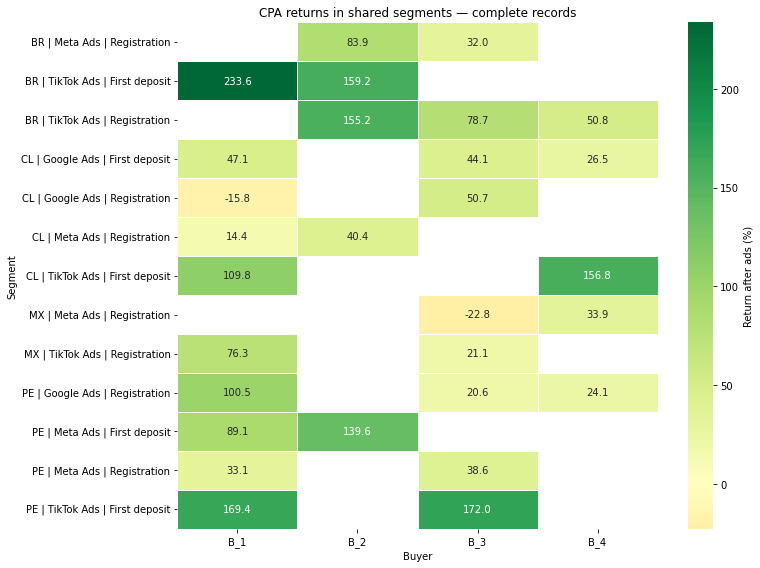

In [11]:
buyers = summarize(analysis_df, "buyer_id")
show(buyers, core)
buyer_models = summarize(analysis_df, ["payout_model", "buyer_id"])
show(buyer_models, core + ["cohort_coverage_pct"])
segment_keys = ["geo", "channel", "optimization_goal", "cpa_rate_usd"]
overlap = (
    campaigns.loc[campaigns["payout_model"].eq("CPA")]
    .groupby(segment_keys)
    .agg(buyers=("buyer_id", "nunique"), campaigns=("campaign_id", "nunique"))
)
shared = overlap.loc[overlap["buyers"].ge(2)].reset_index()
shared_cpa = cpa_data.merge(
    shared[segment_keys], on=segment_keys, validate="many_to_one"
)
comparison = summarize(shared_cpa, segment_keys + ["buyer_id"])
print("Shared CPA segments:", len(shared))
show(
    comparison,
    ["campaigns", "covered_spend", "result", "return_pct", "cohort_coverage_pct"],
)
heat = comparison["return_pct"].reset_index()
heat["segment"] = (
    heat["geo"] + " | " + heat["channel"] + " | " + heat["optimization_goal"]
)
matrix = heat.pivot(index="segment", columns="buyer_id", values="return_pct")
ax = sns.heatmap(
    matrix,
    mask=matrix.isna(),
    annot=True,
    fmt=".1f",
    center=0,
    cmap="RdYlGn",
    linewidths=0.5,
    cbar_kws={"label": "Return after ads (%)"},
)
ax.figure.set_size_inches(11, 8)
ax.set(
    title="CPA returns in shared segments — complete records",
    xlabel="Buyer",
    ylabel="Segment",
)
plt.tight_layout()
plt.show()

B_2 has the highest covered aggregate result and CPA return. B_4 has the lowest aggregate CPA return, yet leads B_1 in CL / TikTok / First deposit and B_3 in MX / Meta / Registration. Leadership depends on context.

Thirteen CPA segments contain at least two buyers; none contains all four. Most buyer/segment cells contain one or two campaigns. Read the heatmap with campaign counts and financial coverage; its colors show observed returns. Landing composition is examined next.

### 4.6. Landing Pages: Repeated Signal and Matched Example

Campaigns using LP_4529: 42
Campaigns with concurrent comparisons: 38
LP_4529 conversion lower: 37


,campaign_median
target_conversion_pct,20.787510
other_conversion_pct,34.514107
difference_pp,-12.560331


,shared_days,target_registrations,other_registrations,target_conversion_pct,other_conversion_pct,other_landing_count,difference_pp
campaign_id,,,,,,,
CMP_4877,19,74,62,18.92,29.03,1,-10.11
CMP_4884,43,116,91,25.00,31.87,1,-6.87
CMP_4926,26,228,495,25.44,41.62,2,-16.18
CMP_4947,32,240,175,22.50,36.57,1,-14.07
CMP_4968,28,70,100,20.00,28.00,2,-8.00
CMP_5003,20,99,154,26.26,38.31,2,-12.05
CMP_5010,22,85,129,16.47,33.33,2,-16.86
CMP_5024,23,73,34,36.99,41.18,1,-4.19
CMP_5031,36,107,96,17.76,45.83,1,-28.08


,campaigns,spend_usd,registrations,ftds,result_usd,return_pct,reg_to_ftd_pct,share_of_covered_cpa_spend_pct
landing_id,,,,,,,,
LP_1047,15,39527.73,2680,866,31472.27,79.62,32.31,16.13
LP_2183,17,31443.34,2605,784,31126.66,98.99,30.10,12.83
LP_3062,26,49362.76,2925,1083,44317.24,89.78,37.03,20.14
LP_4529,21,40270.73,3138,648,13309.27,33.05,20.65,16.43
LP_5716,21,45967.57,2913,909,29732.43,64.68,31.20,18.76
LP_6834,17,38519.50,2963,1063,43070.50,111.81,35.88,15.72


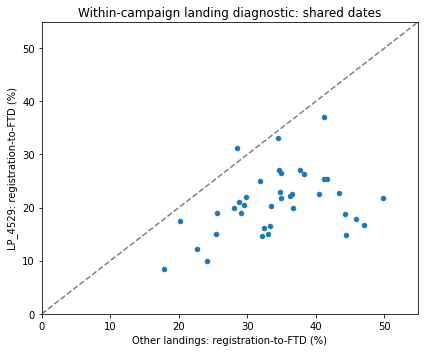

In [12]:
# Review every campaign containing LP_4529, not just one example
landing_pair_rows = []
target_landing = "LP_4529"
target_campaigns = campaigns.loc[
    campaigns["landing_id"].eq(target_landing), "campaign_id"
].unique()
for campaign_id in target_campaigns:
    group = analysis_df.loc[analysis_df["campaign_id"].eq(campaign_id)].copy()
    day_check = group.groupby("acquisition_date")["landing_id"].agg(
        lambda s: target_landing in set(s) and len(set(s)) > 1
    )
    group = group.loc[group["acquisition_date"].isin(day_check.index[day_check])]
    target = group.loc[group["landing_id"].eq(target_landing)]
    other = group.loc[group["landing_id"].ne(target_landing)]
    if target["registrations"].sum() == 0 or other["registrations"].sum() == 0:
        continue
    landing_pair_rows.append(
        {
            "campaign_id": campaign_id,
            "shared_days": group["acquisition_date"].nunique(),
            "target_registrations": target["registrations"].sum(),
            "other_registrations": other["registrations"].sum(),
            "target_conversion_pct": target["ftd_count"].sum()
            / target["registrations"].sum()
            * 100,
            "other_conversion_pct": other["ftd_count"].sum()
            / other["registrations"].sum()
            * 100,
            "other_landing_count": other["landing_id"].nunique(),
        }
    )
landing_pairs = pd.DataFrame(landing_pair_rows).set_index("campaign_id")
landing_pairs["difference_pp"] = (
    landing_pairs["target_conversion_pct"] - landing_pairs["other_conversion_pct"]
)
print("Campaigns using LP_4529:", len(target_campaigns))
print("Campaigns with concurrent comparisons:", len(landing_pairs))
print("LP_4529 conversion lower:", int(landing_pairs["difference_pp"].lt(0).sum()))
display(
    landing_pairs[["target_conversion_pct", "other_conversion_pct", "difference_pp"]]
    .median()
    .to_frame("campaign_median")
)
display(landing_pairs.round(2))

# CPA economics by landing; all metrics below use complete records
landing_cpa = (
    analysis_df.loc[
        analysis_df["payout_model"].eq("CPA") & analysis_df["financial_data_complete"]
    ]
    .groupby("landing_id")
    .agg(
        campaigns=("campaign_id", "nunique"),
        spend_usd=("spend_usd", "sum"),
        registrations=("registrations", "sum"),
        ftds=("ftd_count", "sum"),
        result_usd=("result_after_ads_usd", "sum"),
    )
)
landing_cpa["return_pct"] = landing_cpa["result_usd"] / landing_cpa["spend_usd"] * 100
landing_cpa["reg_to_ftd_pct"] = landing_cpa["ftds"] / landing_cpa["registrations"] * 100
landing_cpa["share_of_covered_cpa_spend_pct"] = (
    landing_cpa["spend_usd"] / landing_cpa["spend_usd"].sum() * 100
)
display(landing_cpa.round(2))

ax = landing_pairs[["target_conversion_pct", "other_conversion_pct"]].plot(
    kind="scatter", x="other_conversion_pct", y="target_conversion_pct", figsize=(6, 5)
)
axis_limit = (
    max(
        landing_pairs["other_conversion_pct"].max(),
        landing_pairs["target_conversion_pct"].max(),
    )
    * 1.1
)
ax.plot([0, axis_limit], [0, axis_limit], linestyle="--", color="grey")
ax.set(
    xlim=(0, axis_limit),
    ylim=(0, axis_limit),
    xlabel="Other landings: registration-to-FTD (%)",
    ylabel="LP_4529: registration-to-FTD (%)",
    title="Within-campaign landing diagnostic: shared dates",
)
plt.tight_layout()
plt.show()

LP_4529 converts less often than pooled concurrent alternatives in **37 of 38 campaigns**. Campaign medians are 20.79% versus 34.51%. Four of its 42 campaigns lack an eligible concurrent comparison. In covered CPA records, the page represents USD 40,270.73 (16.43% of spend) at a 33.05% return; other pages return 64.68%–111.81%.

This repeated association makes page diagnostics and randomized replacement routing a priority. Audit loading, form/offer handoff, tracking, and traffic allocation. The paired campaign evidence is stronger than an isolated aggregate ranking, while creatives and audience allocation can still explain part of the difference.

In [13]:
# Recheck buyer and platform composition after excluding LP_4529
for keys in [["buyer_id"], ["geo", "platform"]]:
    before = summarize(cpa_data, keys)
    after = summarize(cpa_data.loc[cpa_data["landing_id"].ne("LP_4529")], keys)
    sensitivity = pd.DataFrame(
        {
            "all_landings_return_pct": before["return_pct"],
            "without_LP_4529_return_pct": after["return_pct"],
            "remaining_spend": after["recorded_spend"],
        }
    )
    print(keys)
    display(sensitivity.round(2))

['buyer_id']


,all_landings_return_pct,without_LP_4529_return_pct,remaining_spend
buyer_id,,,
B_1,76.73,81.65,73757.44
B_2,123.91,128.56,46228.17
B_3,63.79,79.38,50881.87
B_4,49.64,57.95,33953.42


['geo', 'platform']


all_landings_return_pct  without_LP_4529_return_pct  remaining_spend
geo platform                                                                       
BR  Facebook                    111.85                      111.85         12872.37
    Instagram                    31.99                       51.95          1836.07
    Search                       40.65                       58.85          1133.13
    TikTok                      149.28                      162.60         19535.68
    YouTube                      71.89                       77.53          2636.18
CL  Facebook                    208.15                      208.15          1476.56
    Instagram                    31.42                       37.95          7633.01
    Search                       14.42                       14.42         16701.26
    TikTok                      120.92                      120.92         23125.55
    YouTube                      51.91                       69.28         19428.88
MX  Facebook                    -22.75                         NaN              NaN
    Instagram                    33.90                       33.90          6490.04
    Search                       23.69                       29.43          5609.08
    TikTok                       59.98                       71.70          8008.31
    YouTube                      37.67                       37.67          5193.65
PE  Facebook                     96.30                      100.08         14554.47
    Instagram                    81.07                       79.84         14673.83
    Search                       28.18                       36.72         12441.43
    TikTok                      131.56                      131.56         22460.53
    YouTube                      85.66                       90.33          9010.87

Removing LP_4529 observations raises B_3's CPA return from **63.79% to 79.38%**, close to B_1's **81.65%**. B_2 remains ahead at 128.56%; B_4 rises to 57.95%. The apparent B_1/B_3 gap therefore partly reflects landing composition.

CL and PE / TikTok have zero LP_4529 exposure. CL / Search remains relatively weak after removal; MX / Facebook disappears because its sole campaign uses LP_4529. Exclusion changes the sample and is not a replacement-effect estimate.

In [14]:
# More closely matched creative/settings example, preselected as a case illustration
landing_keys = [
    "campaign_id",
    "buyer_id",
    "geo",
    "channel",
    "platform",
    "device",
    "optimization_goal",
    "payout_model",
]
controlled_keys = landing_keys + [
    "creative_id",
    "offer_id",
    "audience_type",
    "age_group",
    "bid_strategy",
]
overlap = campaigns.groupby(controlled_keys)["landing_id"].nunique()
same_creative = overlap.loc[overlap.ge(2)].reset_index()[controlled_keys]
matched_launches = campaigns.merge(
    same_creative, on=controlled_keys, validate="many_to_one"
)
matched_launches = matched_launches.loc[
    matched_launches["campaign_id"].eq("CMP_5031")
    & matched_launches["creative_id"].eq("CR_4867")
]
example = analysis_df.loc[analysis_df["launch_id"].isin(matched_launches["launch_id"])]
days = example.groupby("acquisition_date").agg(
    landings=("landing_id", "nunique"), complete=("financial_data_complete", "all")
)
common_days = days.index[
    days["landings"].eq(matched_launches["landing_id"].nunique()) & days["complete"]
]
example = example.loc[example["acquisition_date"].isin(common_days)]
print("Shared complete dates:", len(common_days))
show(
    summarize(example, "landing_id"),
    [
        "launches",
        "recorded_spend",
        "registrations",
        "approved_ftds",
        "reg_to_ftd_pct",
        "cost_approved_ftd",
        "result",
        "return_pct",
    ],
)

Shared complete dates: 36


,launches,recorded_spend,registrations,approved_ftds,reg_to_ftd_pct,cost_approved_ftd,result,return_pct
landing_id,,,,,,,,
LP_3062,1,2472.54,96,42,45.83,58.87,2987.46,120.83
LP_4529,1,2425.12,107,18,17.76,134.73,-85.12,-3.51


In CMP_5031 / CR_4867 over 36 shared dates, LP_3062 produces 42 approved FTDs at USD 58.87 each; LP_4529 produces 18 at USD 134.73. LP_4529 has more registrations but fewer depositors. The example supports validation of an appropriate alternative under fixed routing spend.

### 4.7. Statistical Strength of the Landing Signal

Campaigns serve as the sampling unit because daily observations within a campaign are dependent. The exact paired sign test evaluates whether positive and negative conversion differences are equally likely. A campaign-level bootstrap estimates uncertainty in the median paired difference. A Bonferroni adjustment accounts for screening six landing pages. Shared offers and buyers may introduce dependence across campaigns, so these exploratory results require validation through a controlled experiment.

In [15]:
# Exploratory campaign-level sign test and bootstrap
differences = landing_pairs["difference_pp"].to_numpy()
nonzero = differences[differences != 0]
n = len(nonzero)
k = min(int((nonzero < 0).sum()), int((nonzero > 0).sum()))
sign_p = min(1.0, 2 * sum(math.comb(n, j) for j in range(k + 1)) / 2 ** n)
screened_pages = campaigns["landing_id"].nunique()
rng = np.random.default_rng(2026)
bootstrap_medians = np.median(
    rng.choice(differences, size=(10000, len(differences)), replace=True), axis=1
)
interval = np.percentile(bootstrap_medians, [2.5, 97.5])
display(
    pd.Series(
        {
            "paired_campaigns": str(len(differences)),
            "LP_4529_lower_campaigns": str(int((differences < 0).sum())),
            "median_difference_pp": f"{np.median(differences):.2f}",
            "bootstrap_95pct_low_pp": f"{interval[0]:.2f}",
            "bootstrap_95pct_high_pp": f"{interval[1]:.2f}",
            "exact_sign_test_p": f"{sign_p:.3g}",
            "six_page_adjusted_p": f"{min(1.0,sign_p*screened_pages):.3g}",
        }
    ).to_frame("exploratory_statistic")
)

,exploratory_statistic
paired_campaigns,38
LP_4529_lower_campaigns,37
median_difference_pp,-12.56
bootstrap_95pct_low_pp,-15.84
bootstrap_95pct_high_pp,-9.75
exact_sign_test_p,2.84e-10
six_page_adjusted_p,1.7e-09


The median paired conversion difference is −12.56 percentage points, with a campaign-bootstrap interval of −15.84 to −9.75 points. The sign-test result remains small after the six-page screening adjustment. These quantify a consistent within-campaign association under their sampling assumptions. Shared contexts and post-selection make a randomized replacement test the causal decision step; one-campaign device/format differences remain descriptive.

### 4.8. Candidate Segments, Time Trends, and Launch Age

In [16]:
geo_channel = summarize(analysis_df, ["payout_model", "geo", "channel"])
show(geo_channel, core)
candidate_data = cpa_data.loc[
    cpa_data["channel"].eq("TikTok Ads") & cpa_data["geo"].isin(["BR", "PE", "CL"])
].copy()
candidate_monthly = summarize(candidate_data, ["geo", "acquisition_month"])
july = candidate_monthly.xs(pd.Period("2026-07"), level="acquisition_month")[
    "cost_approved_ftd"
]
candidate_monthly["cost_change_vs_july_pct"] = (
    candidate_monthly["cost_approved_ftd"]
    / candidate_monthly.index.get_level_values("geo").map(july)
    - 1
) * 100
show(
    candidate_monthly,
    [
        "campaigns",
        "recorded_spend",
        "approved_ftds",
        "return_pct",
        "cost_approved_ftd",
        "cost_change_vs_july_pct",
        "repeat_pct",
    ],
)
campaign_results = summarize(candidate_data, ["geo", "campaign_id"])
concentration = []
for geo, g in campaign_results.groupby(level="geo"):
    largest = g["result"].idxmax()
    remaining = g.drop(index=largest)
    concentration.append(
        {
            "geo": geo,
            "campaigns": len(g),
            "negative_campaigns": int(g["result"].lt(0).sum()),
            "largest_result_share_pct": g.loc[largest, "result"]
            / g["result"].sum()
            * 100,
            "return_without_largest_pct": safe_ratio(
                remaining["result"].sum(), remaining["covered_spend"].sum(), 100
            ),
        }
    )
display(pd.DataFrame(concentration).set_index("geo").round(2))

campaigns  recorded_spend  approved_ftds    result  return_pct  cost_approved_ftd  repeat_pct  spend_coverage_pct
payout_model          geo channel                                                                                                                      
CPA                   BR  Google Ads          2         6219.06            111   3770.94       60.64              56.03       39.02              100.00
                          Meta Ads            3        16418.03            355  15531.97       94.60              46.25       47.00              100.00
                          TikTok Ads          6        23576.25            653  35193.75      149.28              36.10       51.82              100.00
                      CL  Google Ads         11        44429.00            471  16801.00       37.82              94.33       45.42              100.00
                          Meta Ads            3        10676.37            128   5963.63       55.86              83.41       45.07              100.00
                          TikTok Ads          5        23125.55            393  27964.45      120.92              58.84       47.38              100.00
                      MX  Google Ads          4        11508.05            136   3451.95       30.00              84.62       50.33              100.00
                          Meta Ads            2         8198.85             91   1811.15       22.09              90.10       41.67              100.00
                          TikTok Ads          4        14095.65            205   8454.35       59.98              68.76       47.32              100.00
                      PE  Google Ads          7        31479.36            669  15350.64       48.76              47.05       48.50              100.00
                          Meta Ads            7        32904.93            889  29185.07       88.70              37.10       48.92              100.00
                          TikTok Ads          6        22460.53            743  29549.47      131.56              30.23       46.94              100.00
SPEND_FEE_CONDITIONAL BR  Google Ads          4        12060.52            214   3618.26       30.00              56.36       52.38              100.00
                          Meta Ads            4        19828.11            371   5948.49       30.00              53.45       47.61              100.00
                          TikTok Ads          7        35814.92            962  10744.57       30.00              37.23       50.74              100.00
                      CL  Google Ads          5        12984.01            123   3642.65       30.00             103.78       43.48               93.52
                          Meta Ads            4        19798.11            184   4121.04       30.00             100.27       43.13               69.38
                          TikTok Ads          6        22244.22            321   6279.72       28.23              69.30       45.07              100.00
                      MX  Google Ads          3         9865.50            151   2959.67       30.00              65.33       50.30              100.00
                          Meta Ads            4        17928.96            229   4680.86       30.00              76.48       48.80               87.02
                          TikTok Ads          5        19350.70            337   5805.35       30.00              57.42       52.97              100.00
                      PE  Google Ads          5        18420.50            362   2736.39       30.00              47.75       46.35               49.52
                          Meta Ads            6        18607.95            464   3795.54       30.00              40.42       47.02               67.99
                          TikTok Ads          7        27605.44           1178   5710.49       30.00              22.71       50.27               68.95

campaigns  recorded_spend  approved_ftds  return_pct  cost_approved_ftd  cost_change_vs_july_pct  repeat_pct
geo acquisition_month                                                                                                              
BR  2026-07                    3         6533.37            215      196.17              30.39                     0.00       48.32
    2026-08                    4         8225.23            214      134.16              38.44                    26.48       52.77
    2026-09                    3         8817.65            224      128.63              39.36                    29.54       54.32
CL  2026-07                    2         4464.43             99      188.28              45.10                     0.00       50.89
    2026-08                    5        10363.40            160      100.71              64.77                    43.63       46.93
    2026-09                    2         8297.72            134      109.94              61.92                    37.32       45.27
PE  2026-07                    2         4474.61            164      156.56              27.28                     0.00       51.63
    2026-08                    5         7295.13            224      114.94              32.57                    19.36       45.35
    2026-09                    4        10690.79            355      132.44              30.11                    10.37       45.78

,campaigns,negative_campaigns,largest_result_share_pct,return_without_largest_pct
geo,,,,
BR,6,0,36.75,144.06
CL,5,0,32.65,108.85
PE,6,0,21.36,129.14


CPA / TikTok in BR, CL, and PE is positive in each month and across all 17 campaigns. Each GEO remains positive after removing its largest contributor. These are replication candidates with limited campaign counts and buyer concentration.

BR's approved-FTD cost rises from about USD 30.39 to USD 39.36; CL's rises from USD 45.10 to USD 61.92. CL and PE repeat rates both decline by about 5.6–5.9 percentage points. Diagnose these trends against mature recent cohorts before releasing additional expense. The release gates in section 5 apply to each GEO separately.

In [17]:
# Launch-age comparison on a common set of CPA launches represented in every age band
age_data = cpa_data.copy()
age_data["launch_age_days"] = (
    age_data["acquisition_date"] - age_data["launch_date"]
).dt.days
assert age_data["launch_age_days"].ge(0).all()
age_data["launch_age_band"] = pd.cut(
    age_data["launch_age_days"],
    [-1, 6, 13, 29, np.inf],
    labels=["0–6", "7–13", "14–29", "30+"],
)
launch_bands = (
    age_data.loc[age_data["financial_data_complete"]]
    .groupby("launch_id")["launch_age_band"]
    .nunique()
)
age_launch_ids = launch_bands.index[launch_bands.eq(4)]
age_matched = age_data.loc[
    age_data["launch_id"].isin(age_launch_ids) & age_data["financial_data_complete"]
]
print(
    "Matched launches:",
    len(age_launch_ids),
    "Campaigns:",
    age_matched["campaign_id"].nunique(),
)
age_summary = summarize(age_matched, "launch_age_band")
show(
    age_summary,
    [
        "campaigns",
        "launches",
        "covered_spend",
        "approved_ftds",
        "ctr_pct",
        "cpc_usd",
        "cost_approved_ftd",
        "return_pct",
        "repeat_pct",
    ],
)

# Pair early and later performance within each campaign
campaign_age = summarize(age_matched, ["campaign_id", "launch_age_band"])[
    "cost_approved_ftd"
].unstack()
age_difference = campaign_age["30+"] - campaign_age["0–6"]
print(
    "Median within-campaign cost change, 30+ versus days 0–6 (USD):",
    round(age_difference.median(), 2),
)

Matched launches: 64 Campaigns: 28


,campaigns,launches,covered_spend,approved_ftds,ctr_pct,cpc_usd,cost_approved_ftd,return_pct,repeat_pct
launch_age_band,,,,,,,,,
0–6,28,64,25987.54,554,1.93,1.34,46.91,98.33,49.59
7–13,28,64,26141.19,516,1.91,1.36,50.66,83.69,49.32
14–29,28,64,60201.55,1143,1.93,1.37,52.67,78.58,50.00
30+,28,64,33804.50,656,1.79,1.40,51.53,78.32,48.56


Median within-campaign cost change, 30+ versus days 0–6 (USD): 5.88


The common-support age sample includes 64 launches in 28 campaigns. Pooled approved-FTD cost is USD 46.91 at days 0–6, USD 50.66 at 7–13, USD 52.67 at 14–29, and USD 51.53 at 30+. Early outcomes are therefore not a sufficient scaling baseline.

This compares age since launch, with D30 outcomes observed for each acquisition cohort. The bands have different exposure lengths, and calendar conditions change with age. Read the within-campaign comparison alongside pooled ratios; account for launch maturity when constructing a recent baseline.

### 4.9. Optimization and Targeting Hypotheses

In [18]:
goal_summary = summarize(cpa_data, ["geo", "channel", "optimization_goal"])
show(
    goal_summary,
    ["campaigns", "covered_spend", "cost_approved_ftd", "reg_to_ftd_pct", "return_pct"],
)
for setting in [
    "device",
    "creative_format",
    "audience_type",
    "age_group",
    "bid_strategy",
]:
    print(setting)
    table = summarize(candidate_data, ["geo", "optimization_goal", setting])
    show(
        table,
        [
            "campaigns",
            "covered_spend",
            "approved_ftds",
            "cost_approved_ftd",
            "return_pct",
            "repeat_pct",
        ],
    )

# Joint settings supporting the combined examples in the discussion
joint_settings = summarize(
    candidate_data, ["geo", "optimization_goal", "device", "creative_format"]
)
selected_combinations = [
    ("BR", "First deposit", "Android", "Video"),
    ("PE", "First deposit", "Android", "Static"),
]
print("Selected joint device / format combinations:")
show(
    joint_settings.loc[selected_combinations],
    [
        "campaigns",
        "launches",
        "covered_spend",
        "approved_ftds",
        "cost_approved_ftd",
        "return_pct",
        "repeat_pct",
    ],
)

campaigns  covered_spend  cost_approved_ftd  reg_to_ftd_pct  return_pct
geo channel    optimization_goal                                                                         
BR  Google Ads First deposit              1        3979.40              52.36           33.60       71.89
               Registration               1        2239.66              63.99           31.93       40.65
    Meta Ads   First deposit              1        7047.05              38.30           52.39      134.99
               Registration               2        9370.98              54.80           29.49       64.23
    TikTok Ads First deposit              2       11065.68              32.26           35.48      178.97
               Registration               4       12510.57              40.36           29.42      123.01
CL  Google Ads First deposit              9       38054.85              90.61           32.46       43.48
               Registration               2        6374.15             124.98           25.35        4.01
    Meta Ads   First deposit              1        1476.56              42.19           49.35      208.15
               Registration               2        9199.81              98.92           31.04       31.42
    TikTok Ads First deposit              3       11459.04              55.63           34.23      133.70
               Registration               2       11666.51              62.39           32.15      108.37
MX  Google Ads First deposit              3       10105.54              84.92           29.05       29.53
               Registration               1        1402.51              82.50           40.82       33.33
    Meta Ads   Registration               2        8198.85              90.10           23.70       22.09
    TikTok Ads First deposit              1        1552.74              38.82           43.30      183.37
               Registration               3       12542.91              76.02           18.42       44.70
PE  Google Ads First deposit              2        9799.34              45.79           29.35       52.87
               Registration               5       21680.02              47.65           29.20       46.91
    Meta Ads   First deposit              4       18351.17              30.23           39.23      131.54
               Registration               3       14553.76              51.98           27.05       34.67
    TikTok Ads First deposit              3        8954.39              25.81           34.45      171.26
               Registration               3       13506.14              34.11           25.59      105.24

device


campaigns  covered_spend  approved_ftds  cost_approved_ftd  return_pct  repeat_pct
geo optimization_goal device                                                                                     
BR  First deposit     Android          2       11065.68            343              32.26      178.97       51.20
    Registration      Android          3        9943.89            267              37.24      141.66       52.22
                      Desktop          1        2566.68             43              59.69       50.78       54.17
CL  First deposit     Android          2        9395.95            169              55.60      133.82       48.66
                      iOS              1        2063.09             37              55.76      133.15       51.16
    Registration      Android          1        3045.59             52              58.57      121.96       39.29
                      iOS              1        8620.92            135              63.86      103.57       47.71
PE  First deposit     Android          2        6537.61            254              25.74      171.96       46.83
                      iOS              1        2416.78             93              25.99      169.37       46.23
    Registration      Desktop          2        9038.79            242              37.35       87.41       48.29
                      iOS              1        4467.35            154              29.01      141.31       45.56

creative_format


campaigns  covered_spend  approved_ftds  cost_approved_ftd  return_pct  repeat_pct
geo optimization_goal creative_format                                                                                    
BR  First deposit     Video                    2       11065.68            343              32.26      178.97       51.20
    Registration      Static                   2        3401.50             79              43.06      109.03       53.49
                      Video                    4        9109.07            231              39.43      128.23       52.16
CL  First deposit     Static                   2        6495.89            123              52.81      146.16       50.00
                      Video                    2        4963.15             83              59.80      117.40       47.83
    Registration      Static                   2        7315.79            117              62.53      107.91       46.97
                      Video                    1        4350.72             70              62.15      109.16       42.86
PE  First deposit     Static                   3        6119.44            224              27.32      156.23       48.24
                      Video                    2        2834.95            123              23.05      203.71       43.70
    Registration      Static                   2        3858.45            110              35.08       99.56       44.35
                      Video                    3        9647.69            286              33.73      107.51       48.28

audience_type


... (3 outputs left out)

bid_strategy


campaigns  covered_spend  approved_ftds  cost_approved_ftd  return_pct  repeat_pct
geo optimization_goal bid_strategy                                                                                    
BR  First deposit     Cost cap              1        2940.51            109              26.98      233.62       43.70
                      Lowest cost           1        8125.17            234              34.72      159.19       54.69
    Registration      Cost cap              3        7370.70            173              42.61      111.24       51.31
                      Lowest cost           1        5139.87            137              37.52      139.89       54.00
CL  First deposit     Cost cap              1        3575.09             54              66.21       96.36       45.90
                      Lowest cost           2        7883.95            152              51.87      150.64       50.30
    Registration      Cost cap              1        3045.59             52              58.57      121.96       39.29
                      Lowest cost           1        8620.92            135              63.86      103.57       47.71
PE  First deposit     Cost cap              2        6537.61            254              25.74      171.96       46.83
                      Lowest cost           1        2416.78             93              25.99      169.37       46.23
    Registration      Cost cap              1        2147.43             56              38.35       82.54       45.16
                      Lowest cost           2       11358.71            340              33.41      109.53       47.51

Selected joint device / format combinations:


,,,,campaigns,launches,covered_spend,approved_ftds,cost_approved_ftd,return_pct,repeat_pct
geo,optimization_goal,device,creative_format,,,,,,,
BR,First deposit,Android,Video,2,4,11065.68,343,32.26,178.97,51.20
PE,First deposit,Android,Static,2,3,4954.53,184,26.93,159.96,47.09


First-deposit optimization has stronger observed economics in most GEO/channel comparisons; MX / Google is an exception, and MX / Meta only contains Registration. In PE / TikTok, returns are 171.26% versus 105.24%; approved-FTD costs are USD 25.81 versus USD 34.11.

Setting effects depend on context. BR / First deposit / Android / Video and PE / First deposit / Android / Static each have support from two campaigns. Other format/device combinations often rely on one. Broad audiences warrant replication in PE and CL; bidding strategy has no consistent ordering. Overlapping age labels and repeated campaigns across tables preclude independent demographic or setting claims. Keep test hypotheses specific and change one factor at a time.

### 4.10. Reporting Reconciliation

In [19]:
report_rows = []
for platform, g in analysis_df.groupby("platform"):
    for metric, pc, tc in [
        ("Registrations", "platform_reported_registrations", "registrations"),
        ("FTDs", "platform_reported_ftd", "ftd_count"),
    ]:
        v = g.loc[g["ad_data_match"].eq("both")].dropna(subset=[pc, tc])
        report_rows.append(
            {
                "platform": platform,
                "metric": metric,
                "platform_total": v[pc].sum(),
                "product_total": v[tc].sum(),
                "gap_pct": safe_ratio(v[pc].sum() - v[tc].sum(), v[tc].sum(), 100),
                "excluded_rows": len(g) - len(v),
            }
        )
reporting = pd.DataFrame(report_rows).set_index(["platform", "metric"])
display(reporting.round(2))

platform_total  product_total  gap_pct  excluded_rows
platform  metric                                                              
Facebook  Registrations          3789.0           3953    -4.15              6
          FTDs                   1388.0           1446    -4.01              4
Instagram Registrations          5206.0           5203     0.06              2
          FTDs                   1549.0           1548     0.06              1
Search    Registrations          3741.0           3747    -0.16              1
          FTDs                   1110.0           1110     0.00              0
TikTok    Registrations         16774.0          16771     0.02             12
          FTDs                   5336.0           5330     0.11              1
YouTube   Registrations          4465.0           4463     0.04              2
          FTDs                   1369.0           1369     0.00              1

platform  product    gap  gap_pct  launches
metric        period                                                  
registrations Sep 4–7          85.0      251 -166.0   -66.14        19
              Other dates    3704.0     3702    2.0     0.05        32
ftds          Sep 4–7          24.0       82  -58.0   -70.73        19
              Other dates    1364.0     1364    0.0     0.00        32

Event launches with negative FTD gaps: 17 of 19


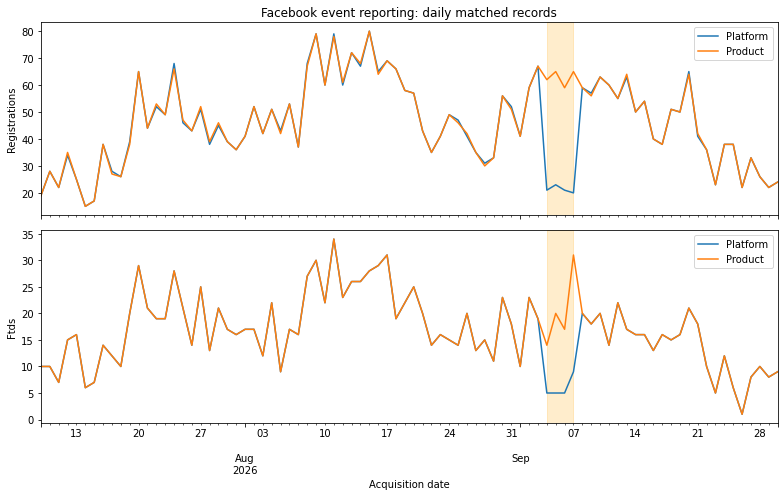

In [20]:
# Identify temporal concentration of Facebook reporting differences
facebook = analysis_df.loc[
    analysis_df["platform"].eq("Facebook") & analysis_df["ad_data_match"].eq("both")
].copy()
facebook_daily = {}
event_rows = []
for metric, platform_col, product_col in [
    ("registrations", "platform_reported_registrations", "registrations"),
    ("ftds", "platform_reported_ftd", "ftd_count"),
]:
    valid = facebook.dropna(subset=[platform_col, product_col]).copy()
    valid["difference"] = valid[platform_col] - valid[product_col]
    valid["absolute_difference"] = valid["difference"].abs()
    daily = valid.groupby("acquisition_date").agg(
        platform_total=(platform_col, "sum"),
        product_total=(product_col, "sum"),
        gap=("difference", "sum"),
        absolute_gap=("absolute_difference", "sum"),
        compared_launches=("launch_id", "nunique"),
    )
    facebook_daily[metric] = daily
    event_window = valid["acquisition_date"].between("2026-09-04", "2026-09-07")
    for period, mask in [("Sep 4–7", event_window), ("Other dates", ~event_window)]:
        subset = valid.loc[mask]
        product_total = subset[product_col].sum()
        event_rows.append(
            {
                "metric": metric,
                "period": period,
                "platform": subset[platform_col].sum(),
                "product": product_total,
                "gap": subset["difference"].sum(),
                "gap_pct": safe_ratio(subset["difference"].sum(), product_total, 100),
                "launches": subset["launch_id"].nunique(),
            }
        )
facebook_event = pd.DataFrame(event_rows).set_index(["metric", "period"])
display(facebook_event.round(2))

event_detail = facebook.loc[
    facebook["acquisition_date"].between("2026-09-04", "2026-09-07")
].copy()
event_detail["ftd_gap"] = (
    event_detail["platform_reported_ftd"] - event_detail["ftd_count"]
)
event_launch_gaps = event_detail.groupby("launch_id")["ftd_gap"].sum()
print(
    "Event launches with negative FTD gaps:",
    int(event_launch_gaps.lt(0).sum()),
    "of",
    len(event_launch_gaps),
)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, metric in zip(axes, ["registrations", "ftds"]):
    facebook_daily[metric][["platform_total", "product_total"]].plot(ax=ax)
    ax.axvspan(
        pd.Timestamp("2026-09-04"),
        pd.Timestamp("2026-09-07"),
        color="orange",
        alpha=0.2,
    )
    ax.set_ylabel(metric.title())
    ax.legend(["Platform", "Product"])
axes[0].set_title("Facebook event reporting: daily matched records")
axes[-1].set_xlabel("Acquisition date")
plt.tight_layout()
plt.show()

Facebook's September 4–7 window contains 24 reported FTDs versus 82 product FTDs (−70.73%) and 85 registrations versus 251 (−66.14%). Nineteen launches are represented; 17 have negative FTD gaps. Outside the window, FTD totals match at 1,364 and registrations differ by +2.

Investigate a shared event-delivery/reporting change around September 4 using deployment logs, attribution settings, timestamps, consent and deduplication checks. The anomaly is concentrated; the quarter average of roughly −4% masks its severity. Backfill confirmed missing events with the data owner and keep the product cohort basis for user outcomes.

## 5. Actions and Test Plan

### 5.1. Delivery and Funding Feasibility

Campaign budgets repeat across launches. Count them once per campaign/date and flag days with incomplete expenses. Last observed activity is a coverage proxy; confirm current status and budget history in the account before changing plans.

In [21]:
assert (
    campaigns.groupby("campaign_id")["campaign_daily_budget_usd"].nunique().eq(1).all()
)
campaign_days = analysis_df.groupby(["campaign_id", "acquisition_date"]).agg(
    spend=("spend_usd", lambda s: s.sum(min_count=1)),
    daily_budget=("campaign_daily_budget_usd", "first"),
    missing_days=("spend_usd", lambda s: s.isna().sum()),
)
delivery = (
    campaign_days.loc[campaign_days["missing_days"].eq(0)]
    .groupby("campaign_id")
    .agg(spend=("spend", "sum"), budget_days=("daily_budget", "sum"))
)
delivery["attainment_pct"] = delivery["spend"] / delivery["budget_days"] * 100
display(
    delivery["attainment_pct"]
    .describe()
    .to_frame("campaign_budget_attainment_pct")
    .round(2)
)
last_date = analysis_df["acquisition_date"].max()
print(
    "Launches observed on final date:",
    analysis_df.loc[
        analysis_df["acquisition_date"].eq(last_date), "launch_id"
    ].nunique(),
)

activity = []
for geo in sorted(cpa_data["geo"].unique()):
    group = cpa_data.loc[
        cpa_data["geo"].eq(geo)
        & cpa_data["platform"].eq("Search")
        & cpa_data["landing_id"].ne("LP_4529")
    ]
    activity.append(
        {
            "role": "Funding source",
            "geo": geo,
            "platform": "Search excluding LP_4529",
            "recorded_spend": group["spend_usd"].sum(),
            "last_observed": group["acquisition_date"].max(),
            "launches_on_final_date": group.loc[
                group["acquisition_date"].eq(last_date), "launch_id"
            ].nunique(),
        }
    )
for geo in ["BR", "CL", "PE"]:
    group = candidate_data.loc[candidate_data["geo"].eq(geo)]
    activity.append(
        {
            "role": "Replication candidate",
            "geo": geo,
            "platform": "TikTok",
            "recorded_spend": group["spend_usd"].sum(),
            "last_observed": group["acquisition_date"].max(),
            "launches_on_final_date": group.loc[
                group["acquisition_date"].eq(last_date), "launch_id"
            ].nunique(),
        }
    )
activity_table = pd.DataFrame(activity).set_index(["role", "geo", "platform"])
display(activity_table.round(2))
source_activity_spend = activity_table.xs("Funding source")["recorded_spend"].sum()
expected_source_spend = cpa_data.loc[
    cpa_data["platform"].eq("Search") & cpa_data["landing_id"].ne("LP_4529"),
    "spend_usd",
].sum()
assert abs(source_activity_spend - expected_source_spend) < 0.01
print("Funding source coverage (USD):", round(source_activity_spend, 2))

,campaign_budget_attainment_pct
count,120.00
mean,25.42
std,0.51
min,24.22
25%,25.10
50%,25.38
75%,25.74
max,27.30


Launches observed on final date: 21


recorded_spend last_observed  launches_on_final_date
role                  geo platform                                                                      
Funding source        BR  Search excluding LP_4529         1133.13    2026-08-20                       0
                      CL  Search excluding LP_4529        16701.26    2026-09-18                       0
                      MX  Search excluding LP_4529         5609.08    2026-09-23                       0
                      PE  Search excluding LP_4529        12441.43    2026-09-27                       0
Replication candidate BR  TikTok                          23576.25    2026-09-30                       2
                      CL  TikTok                          23125.55    2026-09-30                       2
                      PE  TikTok                          22460.53    2026-09-30                       5

Funding source coverage (USD): 35884.9


On fully observed campaign-days, budget attainment averages about 25%; only 21 launches appear on September 30. Budget snapshots, partial delivery, bids, inventory, or audience constraints may explain the gap. Diagnose the cause before treating higher limits as additional delivery capacity.

The plan below applies to the next launch cycle. Funding comes from a confirmed planned Search allocation with relatively weak observed economics, excluding LP_4529 to keep landing remediation separate. If that allocation is absent from the current plan, rebuild the ledger from actual planned expenses.

The source table covers all four GEOs. BR contributes USD 1,133.13, last observed August 20; PE contributes USD 12,441.43, last observed September 27. Together they represent about 38% of the funding baseline, so their current plans also need confirmation before the ledger is applied.

### 5.2. Two Separate Interventions

**A. Landing routing experiment — fixed expense.** Allocate a chosen fraction of LP_4529's existing planned spend to a randomized, context-specific comparison against an appropriate replacement. Hold the combined expense, bids, targeting, and creative fixed. Use approved FTDs and their cost as primary outcomes; monitor mature repeat deposits. Routing changes do not supply the funding pool for intervention B. Complete the landing choice before scaling the same campaigns.

**B. Staged acquisition replication — separate funding.** Use 10% of historical CPA / Search spend excluding LP_4529 as an illustrative funding pool, split equally among BR, PE, and CL / CPA / TikTok. Preserve all remaining allocations and the overall next-cycle expense envelope. The 10% source fraction and equal split are planning assumptions under the 20% reassignment cap.

**Release conditions:** BR must first resolve approved-FTD cost deterioration. CL must resolve both approved-FTD cost deterioration and its repeat-depositor decline. PE must review its repeat-depositor decline. Use comparable mature cohorts for each gate. For each GEO, confirm delivery capacity and a stable landing/creative setup. Funds remain reserved if a gate fails; they are not automatically spent. Initial releases are one third of each allocation, followed by review before later tranches.

In [22]:
# Expense ledger for intervention B only; landing routing keeps its own budget fixed
search_source = cpa_data.loc[
    cpa_data["platform"].eq("Search") & cpa_data["landing_id"].ne("LP_4529")
]
source_baseline = round(search_source["spend_usd"].sum(), 2)
source_fraction = 0.10
reallocation_cap_pct = 20.0
test_pool = round(source_baseline * source_fraction, 2)
share = round(test_pool / 3, 2)
allocations = [share, share, round(test_pool - 2 * share, 2)]
rows = [
    {
        "allocation": "CPA / Search excluding LP_4529",
        "baseline": source_baseline,
        "change": -test_pool,
    }
]
for geo, amount in zip(["BR", "PE", "CL"], allocations):
    base = candidate_data.loc[candidate_data["geo"].eq(geo), "spend_usd"].sum()
    rows.append(
        {"allocation": geo + " / CPA / TikTok", "baseline": base, "change": amount}
    )
ledger = pd.DataFrame(rows).set_index("allocation")
ledger["proposed"] = ledger["baseline"] + ledger["change"]
ledger["initial_tranche"] = ledger["change"].clip(lower=0).div(3).round(2)
total_baseline = analysis_df["spend_usd"].sum()
unchanged = total_baseline - ledger["baseline"].sum()
assert abs(ledger["change"].sum()) < 0.01
assert ledger["proposed"].ge(0).all()
assert test_pool <= total_baseline * reallocation_cap_pct / 100
assert abs(ledger["proposed"].sum() + unchanged - total_baseline) < 0.01
display(ledger.round(2))
print("Reserved test pool (USD):", test_pool)
print(
    "Share of recorded quarterly expense (%):",
    round(test_pool / total_baseline * 100, 2),
)
print("Unchanged total expense envelope (USD):", round(total_baseline, 2))

,baseline,change,proposed,initial_tranche
allocation,,,,
CPA / Search excluding LP_4529,35884.90,-3588.49,32296.41,0.00
BR / CPA / TikTok,23576.25,1196.16,24772.41,398.72
PE / CPA / TikTok,22460.53,1196.16,23656.69,398.72
CL / CPA / TikTok,23125.55,1196.17,24321.72,398.72


Reserved test pool (USD): 3588.49
Share of recorded quarterly expense (%): 0.75
Unchanged total expense envelope (USD): 479600.57


### 5.3. Effect Scenarios and Trade-offs

For routing, assume a 10% experiment allocation from LP_4529 expense, 50/50 routing,
and unchanged payout mix. Apply the treatment yield change only to the treatment
half. The grid includes −10%, 0%, +10%, +20%, and +40% approved-FTD yield per dollar.
Across 19 concurrent CPA campaign comparisons, alternatives show a 38.46% pooled
yield advantage and a 37.10% campaign median. This motivates the +40% case as a
historical association to validate experimentally.

A separate full-quarter benchmark applies the other five CPA landing pages'
aggregate 87.74% return to the entire USD 40,270.73 LP_4529 expense baseline.
It illustrates a result difference of about USD 22,026. That is an upside
opportunity benchmark, not a forecast, confidence limit, or guaranteed upper
bound: landing and traffic composition differ. Its expense scope is much larger
than the small routing test or replication pilot.

For acquisition replication, remove the source's historical yield on the
transferred expense and apply 50%, 75%, or 100% of recipient historical yield to
incremental expense. Expected counts are fractional planning quantities;
mature repeat-depositor quality remains a monitored outcome.


In [23]:
# A: fixed-expense routing sensitivity, using the page's CPA payout mix
bad = cpa_data.loc[
    cpa_data["landing_id"].eq("LP_4529") & cpa_data["financial_data_complete"]
]
routing_expense = round(bad["spend_usd"].sum() * 0.10, 2)
treatment_expense = routing_expense / 2
bad_revenue_yield = bad["total_receivable_usd"].sum() / bad["spend_usd"].sum()
bad_approved_yield = bad["approved_ftd_count"].sum() / bad["spend_usd"].sum()
routing_scenarios = []
for uplift in [-0.10, 0, 0.10, 0.20, 0.40]:
    routing_scenarios.append(
        {
            "assumed_treatment_yield_change_pct": uplift * 100,
            "total_experiment_expense": routing_expense,
            "expected_approved_ftd_change": treatment_expense
            * bad_approved_yield
            * uplift,
            "expected_result_change_usd": treatment_expense
            * bad_revenue_yield
            * uplift,
        }
    )
display(
    pd.DataFrame(routing_scenarios)
    .set_index("assumed_treatment_yield_change_pct")
    .round(2)
)


# Historical approved-FTD yield evidence in concurrent CPA campaign comparisons
yield_rows = []
complete_cpa = cpa_data.loc[cpa_data["financial_data_complete"]]
for campaign_id in complete_cpa.loc[
    complete_cpa["landing_id"].eq("LP_4529"), "campaign_id"
].unique():
    group = complete_cpa.loc[complete_cpa["campaign_id"].eq(campaign_id)]
    shared_dates = group.groupby("acquisition_date")["landing_id"].agg(
        lambda values: "LP_4529" in set(values) and len(set(values)) > 1
    )
    group = group.loc[group["acquisition_date"].isin(shared_dates.index[shared_dates])]
    target = group.loc[group["landing_id"].eq("LP_4529")]
    alternative = group.loc[group["landing_id"].ne("LP_4529")]
    if (
        min(
            target["spend_usd"].sum(),
            alternative["spend_usd"].sum(),
            target["approved_ftd_count"].sum(),
        )
        <= 0
    ):
        continue
    yield_rows.append(
        {
            "campaign_id": campaign_id,
            "target_spend": target["spend_usd"].sum(),
            "target_approved": target["approved_ftd_count"].sum(),
            "alternative_spend": alternative["spend_usd"].sum(),
            "alternative_approved": alternative["approved_ftd_count"].sum(),
        }
    )
yield_comparisons = pd.DataFrame(yield_rows).set_index("campaign_id")
yield_comparisons["relative_yield_uplift_pct"] = (
    (yield_comparisons["alternative_approved"] / yield_comparisons["alternative_spend"])
    / (yield_comparisons["target_approved"] / yield_comparisons["target_spend"])
    - 1
) * 100
pooled_yield_uplift = (
    (
        yield_comparisons["alternative_approved"].sum()
        / yield_comparisons["alternative_spend"].sum()
    )
    / (
        yield_comparisons["target_approved"].sum()
        / yield_comparisons["target_spend"].sum()
    )
    - 1
) * 100
display(
    pd.Series(
        {
            "paired_CPA_campaigns": len(yield_comparisons),
            "median_relative_yield_uplift_pct": yield_comparisons[
                "relative_yield_uplift_pct"
            ].median(),
            "pooled_relative_yield_uplift_pct": pooled_yield_uplift,
        }
    )
    .round(2)
    .to_frame("historical_association")
)

# A: full-quarter benchmark case, separate from the limited routing test
other_pages = complete_cpa.loc[complete_cpa["landing_id"].ne("LP_4529")]
other_page_return = (
    other_pages["result_after_ads_usd"].sum() / other_pages["spend_usd"].sum()
)
full_page_spend = bad["spend_usd"].sum()
observed_page_result = bad["result_after_ads_usd"].sum()
benchmark_result = full_page_spend * other_page_return
landing_benchmark = pd.DataFrame(
    [
        {
            "scope": "Entire quarterly LP_4529 spend at other-page CPA return",
            "expense_baseline_usd": full_page_spend,
            "observed_return_pct": observed_page_result / full_page_spend * 100,
            "assumed_benchmark_return_pct": other_page_return * 100,
            "observed_result_usd": observed_page_result,
            "benchmark_result_usd": benchmark_result,
            "result_difference_usd": benchmark_result - observed_page_result,
        }
    ]
).set_index("scope")
display(landing_benchmark.round(2))

# B: source reduction and recipient marginal yield at unchanged total expense
source_complete = search_source.loc[search_source["financial_data_complete"]]
source_spend = source_complete["spend_usd"].sum()
source_revenue_yield = source_complete["total_receivable_usd"].sum() / source_spend
source_approved_yield = source_complete["approved_ftd_count"].sum() / source_spend
recipient_stats = {}
for geo in ["BR", "PE", "CL"]:
    g = candidate_data.loc[
        candidate_data["geo"].eq(geo) & candidate_data["financial_data_complete"]
    ]
    recipient_stats[geo] = (
        g["total_receivable_usd"].sum() / g["spend_usd"].sum(),
        g["approved_ftd_count"].sum() / g["spend_usd"].sum(),
    )
replication_scenarios = []
for multiplier in [0.50, 0.75, 1.0]:
    added_revenue = sum(
        a * recipient_stats[g][0] * multiplier
        for g, a in zip(["BR", "PE", "CL"], allocations)
    )
    added_approved = sum(
        a * recipient_stats[g][1] * multiplier
        for g, a in zip(["BR", "PE", "CL"], allocations)
    )
    replication_scenarios.append(
        {
            "marginal_yield_vs_history_pct": multiplier * 100,
            "expected_approved_ftd_change": added_approved
            - test_pool * source_approved_yield,
            "expected_result_change_usd": added_revenue
            - test_pool * source_revenue_yield,
        }
    )
display(
    pd.DataFrame(replication_scenarios)
    .set_index("marginal_yield_vs_history_pct")
    .round(2)
)

,total_experiment_expense,expected_approved_ftd_change,expected_result_change_usd
assumed_treatment_yield_change_pct,,,
-10.0,4027.07,-2.99,-267.9
0.0,4027.07,0.00,0.0
10.0,4027.07,2.99,267.9
20.0,4027.07,5.98,535.8
40.0,4027.07,11.96,1071.6


,historical_association
paired_CPA_campaigns,19.00
median_relative_yield_uplift_pct,37.10
pooled_relative_yield_uplift_pct,38.46


,expense_baseline_usd,observed_return_pct,assumed_benchmark_return_pct,observed_result_usd,benchmark_result_usd,result_difference_usd
scope,,,,,,
Entire quarterly LP_4529 spend at other-page CPA return,40270.73,33.05,87.74,13309.27,35335.36,22026.09


,expected_approved_ftd_change,expected_result_change_usd
marginal_yield_vs_history_pct,,
50.0,-1.09,-320.89
75.0,22.17,1777.67
100.0,45.43,3876.22


The routing grid, full-quarter landing benchmark, and replication grid have
different expense scopes. Keep them separate rather than ranking actions by
their headline dollar estimates. The full-quarter case shows why landing
remediation is a first priority; the controlled routing test measures whether
that opportunity is realizable. Historical yields and payout mix remain
assumptions in each scenario. Pause releases when approved-FTD volume or mature
quality worsens.

### 5.4. Monitoring and Decision Rules

| Workstream | Gate / monitor | Review and action |
|---|---|---|
| Landing routing | Randomization, stable total spend and creative, event completeness | Agree sample size and detectable effect before launch; use campaign-aware inference; inspect approved FTD cost and mature D30 repeat rate |
| BR replication | Resolve cost deterioration and verify delivery capacity | Reserve funds until diagnosis is complete; release one third, review, then decide on later tranches |
| CL replication | Resolve both cost deterioration and repeat-rate decline; verify delivery capacity | Reserve funds until both diagnostics are complete; release one third and recheck cost and quality before later tranches |
| PE replication | Review repeat-rate decline and verify delivery capacity | Use the same staged release; evaluate quality before further expense |
| Conditional settlements | Projected final deposit/spend ratio, expense completeness, fee exposure | Review at offer/GEO/month scope; alert below the illustrative 0.75 buffer; recover missing costs and assess September OFF_6137 / CL before incremental spend |
| Facebook reporting | Reconcile Sep 4–7 and verify stable event delivery | Repair/backfill confirmed errors and monitor platform/product differences daily |

Check expense pacing and tracking daily. After two weeks, review early approved FTD cost and volume, allowing for approval delay. Final cohort decisions require D30 maturity; conditional offers also require settlement closure.

Agree recent mature-cohort baselines with comparable launch age and mix. Proposed operational pause triggers are cost per approved FTD +15%, D30 repeat rate −5 percentage points, or affected-portfolio approved FTD volume −10%. These management thresholds trigger diagnosis, not statistical conclusions. Restore or retain allocations if the paying-user objective is not met. July was the strongest observed month; costs and quality deteriorated relative to it. Use a recent, mature, comparable cohort baseline for the pilot after diagnosing that deterioration.

## 6. Conclusions

The case supports three priorities: validate LP_4529 remediation, repair reporting and settlement gaps, and run gated replication tests using platform-level economics and recent unit costs. Removing weak-landing exposure materially changes the B_1/B_3 story; conditional fee headroom is an equally important decision surface for nearly half the expense.

The USD 253,071.40 covered result and the approximately 54.81% assumed-complete return answer different questions. Preserve both bases. Counterfactual landing exclusions, sign tests, age comparisons, and effect scenarios organize uncertainty; controlled experiments and recovered expenses determine the next decision.

Findings apply to the observed portfolio and period; generalization to other campaigns requires further validation. Financial results are accrued after-ad results, with operating costs outside scope. Shared offers and small campaign counts limit inference, current live capacity needs account data, and repeated targeting rows are not independent experiments. Publishing the notebook with its three input CSVs reproduces the calculations and retained charts.